# Лабораторная работа 1 — рабочий ноутбук

**ФИО**: Стасюк Дарья Васильевна

**Файлы данных**: clients.csv и transactions.csv (S27)

## 0. Окружение и настройки

In [90]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from dateutil.utils import today

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "clients.csv"
RAW_TXN = "transactions.csv"

DATA_START, DATA_END = pd.Timestamp("2024-01-01"), pd.Timestamp("2025-07-01")
BASE_START, BASE_END = pd.Timestamp("2024-01-01"), pd.Timestamp("2025-01-01")
EVAL_START, EVAL_END = pd.Timestamp("2025-01-01"), pd.Timestamp("2025-07-01")
REPORT_DATE = pd.Timestamp("2025-06-30")
DAYS_IN_MONTH = 365.25 / 12

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Проверяем кодировку, разделитель, десятичный разделитель, типы, форматы дат и идентификаторы.

In [91]:
with open(RAW_CLIENTS, "r", encoding="utf-8", errors='replace') as f:
    for _ in range(5):
        print(repr(f.readline()))

'client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in\n'
'C000027,1962-08-06,М,ЕКАТЕРИНБУРГ,Зарплатный,Базовый,Дебетовая,27.12.2020,19.03.2022,Зарплата в нашем банке,59800.0,Нет,,,00121,Да\n'
'C003750,1963-07-27,Ж,Новосибирск,Массовый,Золото,Дебетовая,11.05.2020,22.10.2020,Зарплата в нашем банке,47100.0,Да,2025-01,3,00567,Нет\n'
'C003726,1954-11-04,Ж,Новосибирск,Массовый,Базовый,Кредитная,03.02.2013,16.10.2017,Зарплата в другом банке,56900.0,Да,2025-04,3,00323,Да\n'
'C005845,1986-07-24,М,Москва,Массовый,Серебро,Дебетовая,25.12.2011,23.01.2017,Зарплата в другом банке,63800.0,Да,2024-04,,00894,Да\n'


In [92]:
df_clients = pd.read_csv(RAW_CLIENTS, dtype={'client_id': str, 'branch_code': str})
df_clients.head()

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C000027,1962-08-06,М,ЕКАТЕРИНБУРГ,Зарплатный,Базовый,Дебетовая,27.12.2020,19.03.2022,Зарплата в нашем банке,59800.0,Нет,NaN,NaN,00121,Да
1,C003750,1963-07-27,Ж,Новосибирск,Массовый,Золото,Дебетовая,11.05.2020,22.10.2020,Зарплата в нашем банке,47100.0,Да,2025-01,3.0,00567,Нет
2,C003726,1954-11-04,Ж,Новосибирск,Массовый,Базовый,Кредитная,03.02.2013,16.10.2017,Зарплата в другом банке,56900.0,Да,2025-04,3.0,00323,Да
3,C005845,1986-07-24,М,Москва,Массовый,Серебро,Дебетовая,25.12.2011,23.01.2017,Зарплата в другом банке,63800.0,Да,2024-04,NaN,00894,Да
4,C002937,1972-11-04,М,Москва,Зарплатный,Базовый,Дебетовая,07.08.2020,02.05.2021,Зарплата в нашем банке,55500.0,Да,2025-05,3.0,00772,Да


Файл читается как UTF-8, разделитель - запятая, дробная часть через точку. Следовательно, sep, decimal и encoding указывать не нужно, так как параметры read_csv по умолчанию подходят. Идентификаторы и коды читаем как строки, иначе branch_code может потерять ведущие нули.

In [93]:
with open(RAW_TXN, "r", encoding="utf-8", errors='replace') as f:
    for _ in range(5):
        print(repr(f.readline()))

'txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status\n'
'990061;C005930;2023-11-26 13:56:52;2653,01;RUB;��������;5411;�����;�������\n'
'990060;C005209;2023-11-27 17:51:07;138,65;RUB;���������;4111;�����;�������\n'
'990088;C001467;2023-12-12 19:32:40;802,56;RUB;����� � ��������;4814;�����;�������\n'
'990205;C001651;2023-12-21 10:16:21;742,16;RUB;��������;5411;�����;�������\n'


In [94]:
df_transactions = pd.read_csv(RAW_TXN, sep=';', encoding='cp1251', decimal=',', dtype={'txn_id': str, 'client_id': str, 'mcc_code': str})
df_transactions.head()

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990061,C005930,2023-11-26 13:56:52,2653.01,RUB,Продукты,5411,Карта,успешно
1,990060,C005209,2023-11-27 17:51:07,138.65,RUB,Транспорт,4111,Карта,успешно
2,990088,C001467,2023-12-12 19:32:40,802.56,RUB,Связь и интернет,4814,Карта,успешно
3,990205,C001651,2023-12-21 10:16:21,742.16,RUB,Продукты,5411,Карта,успешно
4,990026,C002510,2023-12-28 11:13:51,2712.96,RUB,Одежда и обувь,5651,Карта,успешно


В файле показываются битые места, значит кодировка UTF-8 по умолчанию не подходит (используем encoding='cp1251'). Разделитель - точка с запятой (указываем sep=';'), дробная часть через запятую (указываем decimal=','). Идентификаторы и коды читаем как строки.

## 2. Аудит качества

### 2.1. Объём, типы, ключи, единица наблюдения

In [95]:
DEN = {
    "строк clients":      len(df_clients),
    "уник. client_id":    df_clients["client_id"].nunique(),
    "строк transactions": len(df_transactions),
    "уник. txn_id":       df_transactions["txn_id"].nunique(),
    "уник. client_id в txn": df_transactions["client_id"].nunique(),
}

display(pd.Series(DEN, name="знаменатель").to_frame())

audit = []
def measure(table, field, problem, num, den_key, impact=""):
    den = DEN[den_key]
    audit.append(dict(table=table, field=field, problem=problem, n=int(num),
                      denominator=den_key, den=den, share_pct=round(num / den * 100, 2), impact=impact))
    print(f"{table}.{field}: {problem} — {num} из {den} ({den_key}), {num / den:.2%}")

,знаменатель
строк clients,5729
уник. client_id,5674
строк transactions,622775
уник. txn_id,621275
уник. client_id в txn,5992


Доли по полю считаются от числа строк таблицы.

In [96]:
rows, columns = df_clients.shape
print('Количество строк: ', rows)
print('Количество столбцов: ', columns)

overview = pd.DataFrame({
    'dtype': df_clients.dtypes.astype(str),
    'n_unique': df_clients.nunique(),
    'n_missing': df_clients.isna().sum(),
    'missing_%': (df_clients.isna().mean() * 100).round(2),
    'example': df_clients.iloc[5],
})
overview

Количество строк:  5729
Количество столбцов:  16


,dtype,n_unique,n_missing,missing_%,example
client_id,str,5674,0,0.00,C000597
birth_date,str,4813,0,0.00,1973-06-06
gender,str,2,0,0.00,М
city,str,17,0,0.00,Санкт-Петербург
segment,str,4,0,0.00,Массовый
loyalty_tier,str,4,0,0.00,Золото
card_type,str,3,0,0.00,Дебетовая
registration_date,str,3265,0,0.00,16.03.2017
card_open_date,str,2676,0,0.00,30.09.2020
income_source,str,3,0,0.00,Не указан


In [97]:
rows, columns = df_transactions.shape
print('Количество строк: ', rows)
print('Количество столбцов: ', columns)

overview = pd.DataFrame({
    'dtype': df_transactions.dtypes.astype(str),
    'n_unique': df_transactions.nunique(),
    'n_missing': df_transactions.isna().sum(),
    'missing_%': (df_transactions.isna().mean() * 100).round(2),
    'example': df_transactions.iloc[5],
})
overview


Количество строк:  622775
Количество столбцов:  9


,dtype,n_unique,n_missing,missing_%,example
txn_id,str,621275,0,0.0,100001
client_id,str,5992,0,0.0,C004589
txn_datetime,str,566314,0,0.0,2024-01-01
amount,float64,326372,0,0.0,1504.85
currency,str,3,0,0.0,RUB
category,str,12,0,0.0,Продукты
mcc_code,str,9,0,0.0,5411
channel,str,4,0,0.0,СБП
status,str,3,0,0.0,успешно


### 2.2. Дубли

In [98]:
mask_full_clients = df_clients.duplicated(keep=False)
print('Строк-дубликатов (полные дубли): ', df_clients.duplicated().sum())

Строк-дубликатов (полные дубли):  41


In [99]:
mask_key_clients = df_clients.duplicated(subset=['client_id'], keep=False)
print('Количество дубликатов по client_id: ', df_clients.duplicated(subset=['client_id']).sum())

Количество дубликатов по client_id:  55


In [100]:
conflicts_clients = mask_key_clients & ~mask_full_clients
conflict_rows_clients = df_clients.loc[conflicts_clients].sort_values('client_id')
print("Конфликтующих строк (с одинаковым client_id, но разным содержимым):", len(conflict_rows_clients))
conflict_rows_clients.head(12)

Конфликтующих строк (с одинаковым client_id, но разным содержимым): 28


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
524,C000785,1979-04-17,Ж,Казань,Зарплатный,Серебро,Дебетовая,07.03.2021,05.07.2023,Зарплата в другом банке,83700.0,Да,2024-10,NaN,00583,Да
1947,C000785,1979-04-17,Ж,г. Санкт-Петербург,Зарплатный,Серебро,Дебетовая,07.03.2021,05.07.2023,Зарплата в другом банке,83700.0,Да,2024-10,NaN,00583,Да
4864,C000904,1988-02-15,Ж,Казань,Массовый,Базовый,Дебетовая,08.09.2017,15.07.2023,Не указан,NaN,Нет,NaN,NaN,00644,Нет
4963,C000904,1988-02-15,Ж,Екатеринбург,Массовый,Базовый,Дебетовая,08.09.2017,15.07.2023,Не указан,NaN,Нет,NaN,NaN,00644,Нет
677,C001530,1965-01-20,М,Санкт-Петербург,Зарплатный,Базовый,Дебетовая,21.09.2018,01.10.2018,Зарплата в другом банке,67700.0,Нет,NaN,4.0,00406,Да
2706,C001530,1965-01-20,М,г. Новосибирск,Массовый,Базовый,Дебетовая,21.09.2018,01.10.2018,Зарплата в другом банке,67700.0,Нет,NaN,4.0,00406,Да
4794,C001902,1967-12-13,М,Нижний Новгород,Премиальный,Золото,Дебетовая,27.07.2018,22.10.2019,Не указан,NaN,Нет,NaN,2.0,00444,Да
3094,C001902,1967-12-13,М,Новосибирск,Массовый,Золото,Дебетовая,27.07.2018,22.10.2019,Не указан,NaN,Нет,NaN,2.0,00444,Да
2741,C001967,1994-04-25,Ж,Санкт-Петербург,Премиальный,Серебро,Дебетовая,31.12.2019,22.11.2020,Зарплата в нашем банке,81600.0,Да,2024-02,NaN,00540,Да
5709,C001967,1994-04-25,Ж,Казань,Зарплатный,Серебро,Дебетовая,31.12.2019,22.11.2020,Зарплата в нашем банке,81600.0,Да,2024-02,NaN,00540,Да


In [101]:
mask_full_transactions = df_transactions.duplicated(keep=False)
print('Строк-дубликатов: ', df_transactions.duplicated().sum())

Строк-дубликатов:  1281


In [102]:
mask_key_transactions = df_transactions.duplicated(subset=['txn_id'], keep=False)
print('Количество дубликатов по txn_id: ', df_transactions.duplicated(subset=['txn_id']).sum())

Количество дубликатов по txn_id:  1500


In [103]:
conflicts_transactions = mask_key_transactions & ~mask_full_transactions
conflict_rows_transactions = df_transactions.loc[conflicts_transactions].sort_values('client_id')
print("Конфликтующих строк (с одинаковым txn_id, но разным содержимым):", len(conflict_rows_transactions))
conflict_rows_transactions.head(12)

Конфликтующих строк (с одинаковым txn_id, но разным содержимым): 438


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
152370,251969,C000049,2024-05-15 15:38:56,541.88,RUB,Аптеки,5912,Карта,успешно
152371,251969,C000049,2024-05-15,541.88,RUB,Аптеки,5912,Карта,успешно
609040,712270,C000056,2025-06-18 11:43:38,2619.13,RUB,Связь и Интернет,4814,Карта,успешно
609039,712270,C000056,2025-06-18,2619.13,RUB,Связь и Интернет,4814,Карта,успешно
340512,439644,C000146,2024-10-13,601.56,RUB,Продукты,5411,Карта,успешно
340513,439644,C000146,2024-10-13 14:00:45,601.56,RUB,Продукты,5411,Карта,успешно
3032,103019,C000147,2024-01-05 07:15:24,256.99,RUB,Связь и интернет,4814,СБП,успешно
3033,103019,C000147,2024-01-05,256.99,RUB,Связь и интернет,4814,СБП,успешно
216940,316409,C000165,2024-07-07 14:01:22,94.98,RUB,Транспорт,4111,Онлайн-банк,успешно
216939,316409,C000165,2024-07-07,94.98,RUB,Транспорт,4111,Онлайн-банк,успешно


In [104]:
measure("clients", "все поля", "полный дубль строки", df_clients.duplicated().sum(), "строк clients", "завышает число клиентов")
measure("clients", "client_id", "один id — разное содержимое (конфликт)",
        df_clients.duplicated(subset=["client_id"]).sum() - df_clients.duplicated().sum(), "строк clients",
        "непонятно, какой сегмент/город верный")
measure("transactions", "все поля", "полный дубль строки", df_transactions.duplicated().sum(), "строк transactions", "завышает активность")
measure("transactions", "txn_id", "один id — разное содержимое",
        df_transactions.duplicated(subset=["txn_id"]).sum() - df_transactions.duplicated().sum(), "строк transactions",
        "завышает активность")

clients.все поля: полный дубль строки — 41 из 5729 (строк clients), 0.72%
clients.client_id: один id — разное содержимое (конфликт) — 14 из 5729 (строк clients), 0.24%
transactions.все поля: полный дубль строки — 1281 из 622775 (строк transactions), 0.21%
transactions.txn_id: один id — разное содержимое — 219 из 622775 (строк transactions), 0.04%


В clients 41 строка - полный повтор; ещё у 14 клиентов есть по две разные версии записи (расходятся город и/или сегмент). Актуальность по датам установить не получится (даты сопадают).

В transactions 1281 полный повтор и ещё 219 с одинаковым txn_id, которые отличаются только форматом времени: в одной копии есть дата и время, а в другой только дата. Это та же операция, выгруженная дважды.

### 2.3. Соответствие данных описанию полей из задания

In [105]:
CATEGORICAL_COLS_CLIENTS = [
    'gender', 'city', 'segment',
    'loyalty_tier', 'card_type', 'income_source', 'has_mobile_app', 'satisfaction_score', 'marketing_opt_in',
]

for col in CATEGORICAL_COLS_CLIENTS:
    display(df_clients[col].value_counts(dropna=False).to_frame().T)

print("branch_code: уникальных", df_clients["branch_code"].nunique())

gender,М,Ж
count,2869,2860


city,Москва,Новосибирск,Санкт-Петербург,Казань,Нижний Новгород,Екатеринбург,г. Новосибирск,москва,МОСКВА,Н. Новгород,казань,г. Москва,г. Санкт-Петербург,ЕКАТЕРИНБУРГ,г.Екатеринбург,СПб,Санкт Петербург
count,1075,733,645,565,555,469,221,190,184,179,173,171,127,121,113,110,98


segment,Массовый,Зарплатный,Премиальный,Private
count,2884,1594,1013,238


loyalty_tier,Базовый,Серебро,Золото,Платина
count,2882,1552,967,328


card_type,Дебетовая,Кредитная,Премиальная
count,3968,1273,488


income_source,Зарплата в нашем банке,Не указан,Зарплата в другом банке
count,2547,1599,1583


has_mobile_app,Да,Нет
count,3557,2172


satisfaction_score,NaN,5.0,3.0,2.0,4.0,1.0
count,3380,667,475,471,451,285


marketing_opt_in,Да,Нет
count,5027,702


branch_code: уникальных 839


Видим, что содержимое полей gender, segment, loyalty_tier, card_type, income_source, has_mobile, satisfaction_score и marketing_opt_in соответствует описанию из таблицы. Данные в city необходимо привести к единому написанию.

In [106]:
CATEGORICAL_COLS_TRANSACTIONS = [
    'currency', 'category', 'mcc_code',
    'channel', 'status',
]

for col in CATEGORICAL_COLS_TRANSACTIONS:
    display(df_transactions[col].value_counts(dropna=False).to_frame().T)

currency,RUB,EUR,USD
count,620181,1309,1285


category,Продукты,Одежда и обувь,Транспорт,АЗС,Кафе и рестораны,Развлечения и досуг,Аптеки,Онлайн-сервисы,Связь и интернет,Связь и Интернет,Кафе/рестораны,кафе и рестораны
count,163236,69890,65516,57917,48539,47866,45097,43439,29173,19368,16529,16205


mcc_code,5411,5812,5651,4111,5541,4814,7832,5912,5815
count,162996,81222,69886,65543,57942,48633,47893,45170,43490


channel,Карта,СБП,Токен,Онлайн-банк
count,319384,108933,102900,91558


status,успешно,отклонено,возврат
count,602876,12342,7557


Видим, что содержимое полей currency, mcc_code, channel, status соответствует описанию из таблицы. Данные в category необходимо привести к единому написанию.

In [107]:
measure("transactions", "status", "операция не успешная (отклонено или возврат)",
        (df_transactions["status"] != "успешно").sum(), "строк transactions", "не являются покупками")
print(pd.crosstab(df_transactions["status"], np.sign(df_transactions["amount"]).map({-1: "amount<0", 0: "0", 1: "amount>0"})))

transactions.status: операция не успешная (отклонено или возврат) — 19899 из 622775 (строк transactions), 3.20%
amount     amount<0  amount>0
status                       
возврат        7557         0
отклонено         0     12342
успешно           0    602876


In [108]:
q1, q3 = df_transactions["amount"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"amount: Q1={q1:.2f}, Q3={q3:.2f}, верхняя граница IQR={upper:.2f}")
measure("transactions", "amount", "выше верхней границы IQR", (df_transactions["amount"] > upper).sum(),
        "строк transactions", "проверяем в 3.4")
print(df_transactions["amount"].describe().round(2).to_dict())

inc = df_clients["monthly_income"]
measure("clients", "monthly_income", "значение 0 < x < 1000",
        ((inc > 0) & (inc < 1000)).sum(), "строк clients", "доход занижен в 1000 раз")
print("monthly_income 0<x<1000:", inc[(inc > 0) & (inc < 1000)].describe().round(1).to_dict())

amount: Q1=470.94, Q3=2281.69, верхняя граница IQR=4997.83
transactions.amount: выше верхней границы IQR — 51395 из 622775 (строк transactions), 8.25%
{'count': 622775.0, 'mean': 1893.1, 'std': 2751.3, 'min': -38722.32, '25%': 470.94, '50%': 1076.02, '75%': 2281.69, 'max': 121364.45}
clients.monthly_income: значение 0 < x < 1000 — 157 из 5729 (строк clients), 2.74%
monthly_income 0<x<1000: {'count': 157.0, 'mean': 103.4, 'std': 79.9, 'min': 24.8, '25%': 56.5, '50%': 78.5, '75%': 116.9, 'max': 488.1}


Даты: диапазоны, период транзакций, логика.

In [109]:
txn_dt = pd.to_datetime(df_transactions["txn_datetime"], format="ISO8601")
print("txn_datetime: от", txn_dt.min(), "до", txn_dt.max())
print(txn_dt.dt.to_period("M").value_counts().sort_index().to_string())
measure("transactions", "txn_datetime", "дата вне периода 2024-01-01..2025-06-30",
        ((txn_dt < DATA_START) | (txn_dt >= DATA_END)).sum(), "строк transactions", "вне задачи")
measure("transactions", "txn_datetime", "указана только дата, без времени",
        (df_transactions["txn_datetime"].str.len() == 10).sum(), "строк transactions",
        "для расчёта по месяцам не мешает")

txn_datetime: от 2023-11-26 13:56:52 до 2026-07-31 20:56:45
txn_datetime
2023-11        2
2023-12        3
2024-01    26876
2024-02    33227
2024-03    38464
2024-04    37237
2024-05    34591
2024-06    37518
2024-07    38563
2024-08    39717
2024-09    37899
2024-10    39168
2024-11    37745
2024-12    46732
2025-01    24300
2025-02    29066
2025-03    33860
2025-04    30058
2025-05    26534
2025-06    31139
2025-07        6
2025-08        4
2025-09        3
2025-10        3
2025-11        7
2025-12        7
2026-01        7
2026-02        7
2026-03        5
2026-04        4
2026-05       12
2026-06        4
2026-07        7
Freq: M
transactions.txn_datetime: дата вне периода 2024-01-01..2025-06-30 — 81 из 622775 (строк transactions), 0.01%
transactions.txn_datetime: указана только дата, без времени — 49590 из 622775 (строк transactions), 7.96%


In [110]:
bd = pd.to_datetime(df_clients["birth_date"], format="%Y-%m-%d")
rd = pd.to_datetime(df_clients["registration_date"], format="%d.%m.%Y")
cd = pd.to_datetime(df_clients["card_open_date"], format="%d.%m.%Y")
ll = pd.to_datetime(df_clients["app_last_login"], format="%Y-%m")
age_at_reg = (rd - bd).dt.days / 365.25
print("birth_date", bd.min().date(), "–", bd.max().date(), "| registration", rd.min().date(), "–", rd.max().date(),
      "| card_open", cd.min().date(), "–", cd.max().date(), "| app_last_login", ll.min().date(), "–", ll.max().date())
measure("clients", "card_open_date", "карта открыта раньше прихода в банк", (cd < rd).sum(), "строк clients")
measure("clients", "registration_date", "клиент младше 18 лет на дату регистрации", (age_at_reg < 18).sum(), "строк clients")
measure("clients", "даты", "дата позже среза 30.06.2025",
        ((rd > REPORT_DATE) | (cd > REPORT_DATE) | (ll > REPORT_DATE)).sum(), "строк clients")
print(pd.crosstab(df_clients["has_mobile_app"], df_clients["app_last_login"].isna().rename("login пуст"), margins=True))

birth_date 1936-07-23 – 2003-09-26 | registration 2010-03-18 – 2025-03-18 | card_open 2016-01-01 – 2025-05-16 | app_last_login 2024-01-01 – 2025-06-01
clients.card_open_date: карта открыта раньше прихода в банк — 0 из 5729 (строк clients), 0.00%
clients.registration_date: клиент младше 18 лет на дату регистрации — 28 из 5729 (строк clients), 0.49%
clients.даты: дата позже среза 30.06.2025 — 0 из 5729 (строк clients), 0.00%
login пуст      False  True   All
has_mobile_app                   
Да               3557     0  3557
Нет                 0  2172  2172
All              3557  2172  5729


### 2.4. Связь между таблицами

In [111]:
cl_ids = set(df_clients["client_id"])
tx_ids = df_transactions["client_id"]
orphan = ~tx_ids.isin(cl_ids)
measure("transactions", "client_id", "клиент не найден в справочнике", tx_ids[orphan].nunique(),
        "уник. client_id в txn", "нет признаков клиента и согласия")
measure("transactions", "client_id", "операции клиентов вне справочника", orphan.sum(), "строк transactions")
measure("clients", "client_id", "у клиента нет ни одной операции", len(cl_ids - set(tx_ids)), "уник. client_id")
print("операции клиентов вне справочника по месяцам:")
print(txn_dt[orphan].dt.to_period("M").value_counts().sort_index().to_dict())

transactions.client_id: клиент не найден в справочнике — 326 из 5992 (уник. client_id в txn), 5.44%
transactions.client_id: операции клиентов вне справочника — 26195 из 622775 (строк transactions), 4.21%
clients.client_id: у клиента нет ни одной операции — 8 из 5674 (уник. client_id), 0.14%
операции клиентов вне справочника по месяцам:
{Period('2024-01', 'M'): 1587, Period('2024-02', 'M'): 1932, Period('2024-03', 'M'): 2218, Period('2024-04', 'M'): 2202, Period('2024-05', 'M'): 2001, Period('2024-06', 'M'): 2162, Period('2024-07', 'M'): 2233, Period('2024-08', 'M'): 2247, Period('2024-09', 'M'): 2136, Period('2024-10', 'M'): 2222, Period('2024-11', 'M'): 1809, Period('2024-12', 'M'): 1858, Period('2025-01', 'M'): 756, Period('2025-02', 'M'): 525, Period('2025-03', 'M'): 304, Period('2025-05', 'M'): 1, Period('2025-11', 'M'): 1, Period('2026-01', 'M'): 1}


Клиенты вне справочника активно платят весь 2024 год и почти перестают в I кв. 2025. Справочник содержит
только действующих клиентов на 30.06.2025, значит это, скорее всего, ушедшие клиенты. Их нельзя включить
в кампанию (нет признаков и согласия), а в общей динамике банка они дают дополнительное «падение».

In [112]:
audit_df = pd.DataFrame(audit)
audit_df

,table,field,problem,n,denominator,den,share_pct,impact
0,clients,все поля,полный дубль строки,41,строк clients,5729,0.72,завышает число клиентов
1,clients,client_id,один id — разное содержимое (конфликт),14,строк clients,5729,0.24,"непонятно, какой сегмент/город верный"
2,transactions,все поля,полный дубль строки,1281,строк transactions,622775,0.21,завышает активность
3,transactions,txn_id,один id — разное содержимое,219,строк transactions,622775,0.04,завышает активность
4,transactions,status,операция не успешная (отклонено или возврат),19899,строк transactions,622775,3.20,не являются покупками
5,transactions,amount,выше верхней границы IQR,51395,строк transactions,622775,8.25,проверяем в 3.4
6,clients,monthly_income,значение 0 < x < 1000,157,строк clients,5729,2.74,доход занижен в 1000 раз
7,transactions,txn_datetime,дата вне периода 2024-01-01..2025-06-30,81,строк transactions,622775,0.01,вне задачи
8,transactions,txn_datetime,"указана только дата, без времени",49590,строк transactions,622775,7.96,для расчёта по месяцам не мешает
9,clients,card_open_date,карта открыта раньше прихода в банк,0,строк clients,5729,0.00,


**Выводы по аудиту.**

1. **Период и даты.** 81 операция лежит вне периода (с ноября 2023 г. по июль 2026 г.), у 8% операций нет времени. Форматы дат в `clients` разные по колонкам.
2. **Дубли.** 1500 лишних строк операций (0,24%) и 55 лишних строк клиентов, из них у 14 клиентов противоречивые версии сегмента/города.
3. **Клиенты вне справочника.** 326 клиентов (5,4% от клиентов в операциях), 26 195 операций (4,2%) — скорее всего, ушедшие.

## 3. Препроцессинг

In [113]:
cleaning_log = []
def log(field, issue, scope, n_rows, value_before, action, value_after, rationale):
    cleaning_log.append(dict(field=field, issue=issue, scope=scope, n_rows=int(n_rows),
                             value_before=str(value_before), action=action,
                             value_after=str(value_after), rationale=rationale))

log("branch_code", "код с ведущими нулями читается как число", "все строки", len(df_clients),
    "00121 -> 121 при чтении числом", "исправлено", "строка 00121",
    "код отделения — идентификатор, а не величина; ведущие нули часть кода")

### Дубликаты

In [114]:
n0 = len(df_clients)
df_clients = df_clients.drop_duplicates().reset_index(drop=True)
log("все поля (clients)", "полный дубль строки", "duplicated() по всем полям", n0 - len(df_clients),
    "две одинаковые строки", "удалено", "одна строка",
    "повтор выгрузки, информации не несёт, завышает число клиентов")

conflict_ids = df_clients.loc[df_clients["client_id"].duplicated(), "client_id"].unique()
n0 = len(df_clients)
df_clients = df_clients.drop_duplicates("client_id", keep="first").reset_index(drop=True)
df_clients["id_conflict"] = df_clients["client_id"].isin(conflict_ids)
log("client_id", "один client_id — две разные версии (город/сегмент)",
    f"client_id: {', '.join(sorted(conflict_ids))}", n0 - len(df_clients),
    "2 строки с разным city/segment", "удалено (оставлена первая), клиент помечен id_conflict",
    "1 строка + флаг",
    "актуальную версию установить нельзя; операции клиента сохраняем, в кампанию не берём, т.к. правило групп зависит от сегмента")
print("clients:", len(df_clients), "строк, уникальных id:", df_clients["client_id"].nunique())

clients: 5674 строк, уникальных id: 5674


In [115]:
n0 = len(df_transactions)
df_transactions = df_transactions.drop_duplicates().reset_index(drop=True)
log("все поля (transactions)", "полный дубль строки", "duplicated() по всем полям", n0 - len(df_transactions),
    "две одинаковые строки", "удалено", "одна строка", "повтор выгрузки, завышает активность")

n0 = len(df_transactions)
df_transactions["_has_time"] = df_transactions["txn_datetime"].str.len() > 10
df_transactions = (df_transactions.sort_values("_has_time", ascending=False)
                   .drop_duplicates("txn_id", keep="first")
                   .sort_index().drop(columns="_has_time").reset_index(drop=True))
log("txn_id", "один txn_id в двух копиях: с временем и только с датой", "duplicated(txn_id) после удаления полных дублей",
    n0 - len(df_transactions), "2024-01-03 10:12:47 и 2024-01-03", "удалено (оставлена копия со временем)",
    "2024-01-03 10:12:47", "остальные поля совпадают — это одна операция; копия со временем полнее")
print("transactions:", len(df_transactions), "строк, уникальных txn_id:", df_transactions["txn_id"].nunique())

transactions: 621275 строк, уникальных txn_id: 621275


### 3.1. Типы, даты, числа

In [116]:
df_clients.dtypes

client_id                 str
birth_date                str
gender                    str
city                      str
segment                   str
loyalty_tier              str
card_type                 str
registration_date         str
card_open_date            str
income_source             str
monthly_income        float64
has_mobile_app            str
app_last_login            str
satisfaction_score    float64
branch_code               str
marketing_opt_in          str
id_conflict              bool
dtype: object

In [117]:
date_cols = ['birth_date', 'registration_date', 'card_open_date', 'app_last_login']
for col in date_cols:
    df_clients[col] = pd.to_datetime(
        df_clients[col], errors="coerce"
    )
df_clients.dtypes

/var/folders/7c/y58c7_y54bgd0y00_qct5rgm0000gn/T/ipykernel_88797/2307823666.py:3: UserWarning: Parsing dates in %d.%m.%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_clients[col] = pd.to_datetime(
/var/folders/7c/y58c7_y54bgd0y00_qct5rgm0000gn/T/ipykernel_88797/2307823666.py:3: UserWarning: Parsing dates in %d.%m.%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_clients[col] = pd.to_datetime(


client_id                        str
birth_date            datetime64[us]
gender                           str
city                             str
segment                          str
loyalty_tier                     str
card_type                        str
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source                    str
monthly_income               float64
has_mobile_app                   str
app_last_login        datetime64[us]
satisfaction_score           float64
branch_code                      str
marketing_opt_in                 str
id_conflict                     bool
dtype: object

In [118]:
for col in ["birth_date", "registration_date", "card_open_date"]:
    print(f"{col}: NaT {df_clients[col].isna().sum()}, от {df_clients[col].min():%Y-%m-%d} до {df_clients[col].max():%Y-%m-%d}")
print("app_last_login: непустых", df_clients["app_last_login"].notna().sum(), "| у клиентов с приложением",
      (df_clients["has_mobile_app"] == "Да").sum())
assert df_clients[["birth_date", "registration_date", "card_open_date"]].isna().sum().sum() == 0
log("birth_date, registration_date, card_open_date, app_last_login", "даты строками в разных форматах по колонкам",
    "все строки", len(df_clients), "1962-08-06 / 27.12.2020 / 2025-01", "исправлено (тип)", "datetime",
    "формат каждой колонки единый (см. раздел 1), pandas определил его верно: 0 NaT, диапазоны правдоподобны")

birth_date: NaT 0, от 1936-07-23 до 2003-09-26
registration_date: NaT 0, от 2010-03-18 до 2025-03-18
card_open_date: NaT 0, от 2016-01-01 до 2025-05-16
app_last_login: непустых 3526 | у клиентов с приложением 3526


Перед преобразованием значений Да/Нет в колонках has_mobile_app и marketing_opt_in проверяем, что других значений в колонках нет.

In [119]:
df_clients['has_mobile_app'].value_counts().to_frame()

,count
has_mobile_app,
Да,3526
Нет,2148


In [120]:
df_clients['marketing_opt_in'].value_counts().to_frame()

,count
marketing_opt_in,
Да,4978
Нет,696


In [121]:
bool_cols = ['has_mobile_app', 'marketing_opt_in']
for col in bool_cols:
    df_clients[col] = df_clients[col].map({'Да': True, 'Нет': False})

df_clients.dtypes

client_id                        str
birth_date            datetime64[us]
gender                           str
city                             str
segment                          str
loyalty_tier                     str
card_type                        str
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source                    str
monthly_income               float64
has_mobile_app                  bool
app_last_login        datetime64[us]
satisfaction_score           float64
branch_code                      str
marketing_opt_in                bool
id_conflict                     bool
dtype: object

In [122]:
df_clients['has_mobile_app'].value_counts().to_frame()

,count
has_mobile_app,
True,3526
False,2148


In [123]:
df_clients['marketing_opt_in'].value_counts().to_frame()

,count
marketing_opt_in,
True,4978
False,696


In [124]:
log("has_mobile_app, marketing_opt_in", "да/нет строкой", "все строки", len(df_clients), "Да/Нет",
    "исправлено (тип)", "True/False", "других значений нет, смысл не меняется")

df_transactions["txn_datetime"] = pd.to_datetime(df_transactions["txn_datetime"], format="ISO8601")
log("txn_datetime", "дата-время строкой; у части строк только дата",
    "все строки", len(df_transactions), "2024-01-01 / 2024-01-01 13:14:54", "исправлено (тип), время не восстанавливалось",
    "datetime (00:00 там, где времени нет)", "для помесячной метрики достаточно даты; время в анализе не используется")

Числа: доход с кодом пропуска `-999` и доход, записанный в тысячах рублей (найдены в 2.1 и 2.3).

In [125]:
inc = df_clients["monthly_income"]
mask_code = inc == -999
log("monthly_income", "код пропуска -999", "monthly_income == -999", mask_code.sum(), "-999", "заменено на NaN",
    "NaN", "отрицательного дохода не бывает; -999 — служебный код «нет данных»")
df_clients.loc[mask_code, "monthly_income"] = np.nan

mask_k = (df_clients["monthly_income"] > 0) & (df_clients["monthly_income"] < 1000)
ratio = df_clients.loc[mask_k, "monthly_income"].median() * 1000 / df_clients.loc[~mask_k, "monthly_income"].median()
print(f"медиана малых значений ×1000 / медиана остальных = {ratio:.2f}")
log("monthly_income", "доход указан в тысячах рублей", "0 < monthly_income < 1000", mask_k.sum(),
    f"{df_clients.loc[mask_k, 'monthly_income'].min()}–{df_clients.loc[mask_k, 'monthly_income'].max()}",
    "исправлено (×1000)", "24 800–488 100",
    "доход < 1000 руб./мес. неправдоподобен; ×1000 даёт распределение, совпадающее с остальными (отношение медиан ≈ 1)")
df_clients.loc[mask_k, "monthly_income"] *= 1000
df_clients["monthly_income"].describe().round(0)

медиана малых значений ×1000 / медиана остальных = 1.03


count      5110.0
mean      99123.0
std       81417.0
min       16900.0
25%       54800.0
50%       76200.0
75%      111900.0
max      968600.0
Name: monthly_income, dtype: float64

### 3.2. Категориальные признаки

In [126]:
df_clients['city'].unique()

<StringArray>
[      'ЕКАТЕРИНБУРГ',        'Новосибирск',             'Москва',    'Санкт-Петербург',            ' москва',       'Екатеринбург', 'г. Санкт-Петербург',
    'Санкт Петербург',             'МОСКВА',     'г.Екатеринбург',             'Казань',    'Нижний Новгород',          'г. Москва',        'Н. Новгород',
     'г. Новосибирск',             'казань',                'СПб']
Length: 17, dtype: str

В колонке city наблюдается разнобой в написании названий городов. Исправляем при помощи словаря.

In [127]:
CITY_FIX = {
    ("ЕКАТЕРИНБУРГ", "г.Екатеринбург"): "Екатеринбург",
    ("г. Новосибирск",): "Новосибирск",
    (" москва", "МОСКВА", "г. Москва"): "Москва",
    ("г. Санкт-Петербург", "Санкт Петербург", "СПб"): "Санкт-Петербург",
    ("казань",): "Казань",
    ("Н. Новгород",): "Нижний Новгород"
}

flat_city_fix = {
    variant: correct
    for keys, correct in CITY_FIX.items()
    for variant in (keys if isinstance(keys, (tuple, list)) else [keys])
}

df_clients['city'] = df_clients['city'].replace(flat_city_fix)

In [128]:
df_clients['city'].unique()

<StringArray>
['Екатеринбург', 'Новосибирск', 'Москва', 'Санкт-Петербург', 'Казань', 'Нижний Новгород']
Length: 6, dtype: str

In [129]:
df_transactions['category'].unique()

<StringArray>
[           'Продукты',           'Транспорт',    'Связь и интернет',      'Одежда и обувь', 'Развлечения и досуг',              'Аптеки',
                 'АЗС',    'кафе и рестораны',      'Онлайн-сервисы',    'Кафе и рестораны',      'Кафе/рестораны',    'Связь и Интернет']
Length: 12, dtype: str

В колонке category также наблюдается разнобой в написании категорий. Исправляем при помощи словаря.

In [130]:
CATEGORY_FIX = {
    ("Связь и Интернет",): "Связь и интернет",
    ("кафе и рестораны", "Кафе/рестораны"): "Кафе и рестораны",
}

flat_category_fix = {
    variant: correct
    for keys, correct in CATEGORY_FIX.items()
    for variant in (keys if isinstance(keys, (tuple, list)) else [keys])
}


df_transactions['category'] = df_transactions['category'].replace(flat_category_fix)

In [131]:
df_transactions['category'].unique()

<StringArray>
['Продукты', 'Транспорт', 'Связь и интернет', 'Одежда и обувь', 'Развлечения и досуг', 'Аптеки', 'АЗС', 'Кафе и рестораны', 'Онлайн-сервисы']
Length: 9, dtype: str

In [132]:
print(df_transactions.groupby(['category', 'mcc_code']).size().index.tolist())

[('АЗС', '4111'), ('АЗС', '4814'), ('АЗС', '5411'), ('АЗС', '5541'), ('АЗС', '5651'), ('АЗС', '5812'), ('АЗС', '5815'), ('АЗС', '5912'), ('АЗС', '7832'), ('Аптеки', '4111'), ('Аптеки', '4814'), ('Аптеки', '5411'), ('Аптеки', '5541'), ('Аптеки', '5651'), ('Аптеки', '5812'), ('Аптеки', '5815'), ('Аптеки', '5912'), ('Аптеки', '7832'), ('Кафе и рестораны', '4111'), ('Кафе и рестораны', '4814'), ('Кафе и рестораны', '5411'), ('Кафе и рестораны', '5541'), ('Кафе и рестораны', '5651'), ('Кафе и рестораны', '5812'), ('Кафе и рестораны', '5815'), ('Кафе и рестораны', '5912'), ('Кафе и рестораны', '7832'), ('Одежда и обувь', '4111'), ('Одежда и обувь', '4814'), ('Одежда и обувь', '5411'), ('Одежда и обувь', '5541'), ('Одежда и обувь', '5651'), ('Одежда и обувь', '5812'), ('Одежда и обувь', '5815'), ('Одежда и обувь', '5912'), ('Одежда и обувь', '7832'), ('Онлайн-сервисы', '4111'), ('Онлайн-сервисы', '4814'), ('Онлайн-сервисы', '5411'), ('Онлайн-сервисы', '5541'), ('Онлайн-сервисы', '5651'), ('Он

In [133]:
per_cat = df_transactions.groupby("category", dropna=False)["mcc_code"].nunique(dropna=False)
print("MCC на категорию:")
print(per_cat.sort_values(ascending=False))

MCC на категорию:
category
АЗС                    9
Аптеки                 9
Кафе и рестораны       9
Одежда и обувь         9
Онлайн-сервисы         9
Продукты               9
Развлечения и досуг    9
Связь и интернет       9
Транспорт              9
Name: mcc_code, dtype: int64


In [135]:
per_mcc = df_transactions.groupby("mcc_code", dropna=False)["category"].nunique(dropna=False)
conflict_mcc = per_mcc[per_mcc > 1]

n_unique_mcc = int(df_transactions["mcc_code"].nunique(dropna=True))
print(f"уникальных MCC = {n_unique_mcc}")
print(f"MCC, у которых >1 категории = {len(conflict_mcc)} "
      f"({len(conflict_mcc)/n_unique_mcc:.2%} от уникальных MCC)")
print(conflict_mcc.sort_values(ascending=False).head(10))


ct = pd.crosstab(df_transactions["mcc_code"], df_transactions["category"], dropna=False)
print(ct)

def highlight_dominant(row, threshold=0.8):
    total = row.sum()
    if total == 0 or pd.isna(total):
        return [""] * len(row)
    return [
        "background-color: #90EE90; font-weight: bold" if v / total > threshold else ""
        for v in row
    ]

styled = ct.style.apply(highlight_dominant, axis=1)
styled


уникальных MCC = 9
MCC, у которых >1 категории = 9 (100.00% от уникальных MCC)
mcc_code
4111    9
4814    9
5411    9
5541    9
5651    9
5812    9
5815    9
5912    9
7832    9
Name: category, dtype: int64
category    АЗС  Аптеки  Кафе и рестораны  Одежда и обувь  Онлайн-сервисы  Продукты  Развлечения и досуг  Связь и интернет  Транспорт
mcc_code                                                                                                                             
4111         21      13                27              21              12        50                   24                10      65214
4814         23      13                31              19              20        49                   15             48318         22
5411         23       9                28              22              18    162400                   20                19         25
5541      57627      14                27              27              19        52                   19                11 

category,АЗС,Аптеки,Кафе и рестораны,Одежда и обувь,Онлайн-сервисы,Продукты,Развлечения и досуг,Связь и интернет,Транспорт
mcc_code,,,,,,,,,
4111,21,13,27,21,12,50,24,10,65214
4814,23,13,31,19,20,49,15,48318,22
5411,23,9,28,22,18,162400,20,19,25
5541,57627,14,27,27,19,52,19,11,19
5651,20,9,18,69561,17,57,22,13,20
5812,27,12,80845,21,17,47,13,8,19
5815,17,13,30,19,43200,54,14,15,21
5912,18,44911,31,25,13,46,10,14,12
7832,13,14,24,25,16,49,47619,10,15


Каждый MCC почти целиком приходится на одну категорию; расхождения — равномерный шум.

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [136]:
n = len(df_clients)
miss = df_clients.isna().sum()
miss = pd.DataFrame({"n_missing": miss, "доля_%": (miss / n * 100).round(1)}).query("n_missing > 0")
miss

,n_missing,доля_%
monthly_income,564,9.9
app_last_login,2148,37.9
satisfaction_score,3352,59.1


Видим пропуски в satisfaction_score, app_last_login и monthly_income.

In [137]:
cols = ["client_id", "has_mobile_app", "app_last_login",
        "registration_date", "segment", "city"]
df_clients[cols].head(15)

,client_id,has_mobile_app,app_last_login,registration_date,segment,city
0,C000027,False,NaT,2020-12-27,Зарплатный,Екатеринбург
1,C003750,True,2025-01-01,2020-05-11,Массовый,Новосибирск
2,C003726,True,2025-04-01,2013-02-03,Массовый,Новосибирск
3,C005845,True,2024-04-01,2011-12-25,Массовый,Москва
4,C002937,True,2025-05-01,2020-08-07,Зарплатный,Москва
5,C000597,True,2024-06-01,2017-03-16,Массовый,Санкт-Петербург
6,C001564,False,NaT,2014-09-27,Массовый,Екатеринбург
7,C000015,True,2024-01-01,2021-02-11,Зарплатный,Москва
8,C005360,True,2024-05-01,2022-02-03,Зарплатный,Екатеринбург
9,C004465,True,2024-08-01,2016-02-18,Зарплатный,Москва


In [138]:
mask = df_clients["app_last_login"].isna()
cols = ["client_id", "has_mobile_app", "app_last_login",
        "registration_date", "segment", "city"]
df_clients.loc[mask, cols].head(20)

,client_id,has_mobile_app,app_last_login,registration_date,segment,city
0,C000027,False,NaT,2020-12-27,Зарплатный,Екатеринбург
6,C001564,False,NaT,2014-09-27,Массовый,Екатеринбург
14,C004789,False,NaT,2017-07-07,Премиальный,Санкт-Петербург
15,C002433,False,NaT,2016-09-22,Массовый,Санкт-Петербург
17,C002451,False,NaT,2016-12-14,Массовый,Москва
22,C001687,False,NaT,2017-12-15,Премиальный,Казань
23,C005285,False,NaT,2017-12-29,Массовый,Казань
25,C002070,False,NaT,2019-10-13,Премиальный,Казань
26,C003116,False,NaT,2015-10-03,Зарплатный,Санкт-Петербург
28,C005583,False,NaT,2022-05-08,Зарплатный,Москва


In [139]:
pd.crosstab(
    df_clients["has_mobile_app"],
    df_clients["app_last_login"].isna(),
    dropna=False, margins=True
)

app_last_login,False,True,All
has_mobile_app,,,
False,0,2148,2148
True,3526,0,3526
All,3526,2148,5674


In [140]:
for col in ["satisfaction_score", "monthly_income"]:
    print(f"\nдоля пропусков {col} по сегменту, % (знаменатель — клиенты сегмента):")
    print((df_clients.groupby("segment")[col].apply(lambda s: s.isna().mean() * 100)).round(1).to_dict())
    print(f"доля пропусков {col} по наличию приложения, %:",
          (df_clients.groupby("has_mobile_app")[col].apply(lambda s: s.isna().mean() * 100)).round(1).to_dict())


доля пропусков satisfaction_score по сегменту, % (знаменатель — клиенты сегмента):
{'Private': 33.2, 'Зарплатный': 60.9, 'Массовый': 64.9, 'Премиальный': 45.8}
доля пропусков satisfaction_score по наличию приложения, %: {False: 58.4, True: 59.5}

доля пропусков monthly_income по сегменту, % (знаменатель — клиенты сегмента):
{'Private': 11.5, 'Зарплатный': 5.4, 'Массовый': 12.6, 'Премиальный': 9.2}
доля пропусков monthly_income по наличию приложения, %: {False: 9.2, True: 10.4}


In [141]:
n = len(df_transactions)

miss = pd.DataFrame({
    "n_missing": df_transactions.isna().sum(),
    "missing_rate": df_transactions.isna().sum() / n,
}).sort_values("missing_rate", ascending=False)

miss[miss["n_missing"] > 0]

,n_missing,missing_rate


app_last_login - пропуск у клиентов без приложения: нет приложения - нет входа. Заполнять ничем не нужно, решение - оставить.


satisfaction_score - шкала порядковая, любая подстановка исказит распределение оценок. Заполнять не будем.


monthly_income - доля пропусков умеренно различается по сегментам и не зависит от наличия приложения. Не заполняем.

В таблице transactions пропусков нету.

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

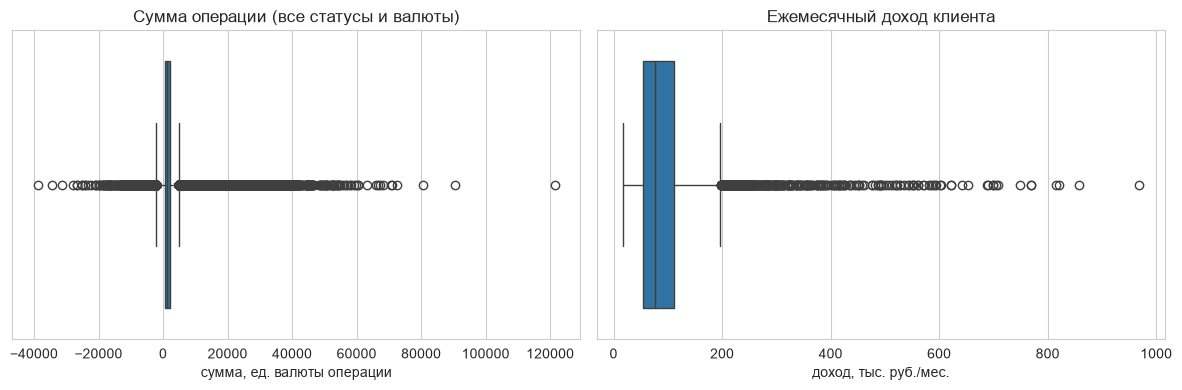

amount > 4997: 51281 из 621275 (8.25%)
доли категорий среди крупных операций, %: {'Одежда и обувь': 55.6, 'Развлечения и досуг': 17.8, 'АЗС': 10.9, 'Кафе и рестораны': 10.0}
топ-5 сумм: [121364.0, 90387.0, 80642.0, 72437.0, 70976.0]

monthly_income > 197550: 385 из 5110 непустых
сегменты клиентов с доходом выше границы: {'Private': 191, 'Премиальный': 183, 'Зарплатный': 8, 'Массовый': 3}


In [142]:
q1, q3 = df_transactions["amount"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df_transactions["amount"], ax=axes[0])
axes[0].set(title="Сумма операции (все статусы и валюты)", xlabel="сумма, ед. валюты операции")
sns.boxplot(x=df_clients["monthly_income"] / 1000, ax=axes[1])
axes[1].set(title="Ежемесячный доход клиента", xlabel="доход, тыс. руб./мес.")
plt.tight_layout(); plt.show()

big = df_transactions[df_transactions["amount"] > upper]
print(f"amount > {upper:.0f}: {len(big)} из {len(df_transactions)} ({len(big)/len(df_transactions):.2%})")
print("доли категорий среди крупных операций, %:", (big["category"].value_counts(normalize=True) * 100).round(1).head(4).to_dict())
print("топ-5 сумм:", df_transactions["amount"].nlargest(5).round(0).tolist())

inc = df_clients["monthly_income"]
q1i, q3i = inc.quantile([0.25, 0.75]); up_i = q3i + 1.5 * (q3i - q1i)
print(f"\nmonthly_income > {up_i:.0f}: {(inc > up_i).sum()} из {inc.notna().sum()} непустых")
print("сегменты клиентов с доходом выше границы:", df_clients.loc[inc > up_i, "segment"].value_counts().to_dict())

amount: крупные суммы — это в основном «Одежда и обувь» и другие категории, где разовый чек в десятки тысяч
  правдоподобен; явных ошибок (нули, неправдоподобные порядки) нет. Источник подтвердить нельзя, но метрика
  активности — **число операций**, а не сумма, поэтому выбросы по сумме на выводы не влияют. Оставляем.

Отрицательные суммы — это ровно возвраты, не выбросы. Они уходят фильтром по статусу.


monthly_income: высокие доходы приходятся на Private и Премиальный сегменты — это ожидаемо. Оставляем.

In [143]:
log("amount", "суммы выше верхней границы IQR", f"amount > {upper:.0f}", (df_transactions["amount"] > upper).sum(),
    f"до {df_transactions['amount'].max():.0f}", "оставлено", "без изменений",
    "правдоподобные крупные чеки; метрика считает число операций, а не сумму, выводы не чувствительны")
log("monthly_income", "доход выше границы IQR", f"monthly_income > {up_i:.0f}", (inc > up_i).sum(),
    f"до {inc.max():.0f}", "оставлено", "без изменений", "высокие доходы у Private/Премиальных ожидаемы")

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [144]:
funnel = [("после удаления дублей", len(df_transactions))]

n0 = len(df_transactions)
out_period = (df_transactions["txn_datetime"] < DATA_START) | (df_transactions["txn_datetime"] >= DATA_END)
ex = df_transactions.loc[out_period, "txn_datetime"]
df_transactions = df_transactions[~out_period].reset_index(drop=True)
log("txn_datetime", "операции вне периода данных", "txn_datetime < 2024-01-01 или ≥ 2025-07-01", n0 - len(df_transactions),
    f"{ex.min():%Y-%m-%d} … {ex.max():%Y-%m-%d}", "удалено", "2024-01-01 … 2025-06-30",
    "по условию данные охватывают только этот период; операции в будущем относительно среза — ошибка выгрузки")
funnel.append(("в периоде 2024-01-01..2025-06-30", len(df_transactions)))

df_transactions["in_directory"] = df_transactions["client_id"].isin(df_clients["client_id"])
log("client_id (transactions)", "клиент отсутствует в справочнике", "client_id не в clients",
    (~df_transactions["in_directory"]).sum(), f"{df_transactions.loc[~df_transactions['in_directory'], 'client_id'].nunique()} клиентов",
    "оставлено, помечено in_directory=False, исключено из метрики", "флаг",
    "нет признаков и согласия; вероятно, ушедшие клиенты — их нельзя вернуть кампанией по этой базе")
step = df_transactions[df_transactions["in_directory"]]
funnel.append(("клиент есть в справочнике", len(step)))

step = step[step["status"] == "успешно"]
funnel.append(("статус «успешно» (без отказов и возвратов)", len(step)))
log("status", "отказы и возвраты — не покупки", "status ≠ «успешно»",
    ((df_transactions["status"] != "успешно") & df_transactions["in_directory"]).sum(), "отклонено / возврат",
    "оставлено в таблице, исключено из метрики", "фильтр", "активность = совершённые покупки; отказ — не покупка, возврат — отмена покупки")
log("currency", "операции в EUR/USD, курса нет", "currency ≠ RUB", (df_transactions["currency"] != "RUB").sum(),
    "EUR/USD", "оставлено", "без изменений", "метрика — число операций, валюта на неё не влияет; суммы в анализе считаем только по RUB")

purchases = step.copy()
funnel_df = pd.DataFrame(funnel, columns=["шаг", "строк"])
funnel_df["выбыло"] = -funnel_df["строк"].diff().fillna(0).astype(int)
funnel_df

,шаг,строк,выбыло
0,после удаления дублей,621275,0
1,в периоде 2024-01-01..2025-06-30,621194,81
2,клиент есть в справочнике,595058,26136
3,статус «успешно» (без отказов и возвратов),576038,19020


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [145]:
cleaning_log = pd.DataFrame(cleaning_log, columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

In [147]:
cleaning_log

,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,branch_code,код с ведущими нулями читается как число,все строки,5729,00121 -> 121 при чтении числом,исправлено,строка 00121,"код отделения — идентификатор, а не величина; ..."
1,все поля (clients),полный дубль строки,duplicated() по всем полям,41,две одинаковые строки,удалено,одна строка,"повтор выгрузки, информации не несёт, завышает..."
2,client_id,один client_id — две разные версии (город/сегм...,"client_id: C000785, C000904, C001530, C001902,...",14,2 строки с разным city/segment,"удалено (оставлена первая), клиент помечен id_...",1 строка + флаг,актуальную версию установить нельзя; операции ...
3,все поля (transactions),полный дубль строки,duplicated() по всем полям,1281,две одинаковые строки,удалено,одна строка,"повтор выгрузки, завышает активность"
4,txn_id,один txn_id в двух копиях: с временем и только...,duplicated(txn_id) после удаления полных дублей,219,2024-01-03 10:12:47 и 2024-01-03,удалено (оставлена копия со временем),2024-01-03 10:12:47,остальные поля совпадают — это одна операция; ...
5,"birth_date, registration_date, card_open_date,...",даты строками в разных форматах по колонкам,все строки,5674,1962-08-06 / 27.12.2020 / 2025-01,исправлено (тип),datetime,"формат каждой колонки единый (см. раздел 1), p..."
6,"has_mobile_app, marketing_opt_in",да/нет строкой,все строки,5674,Да/Нет,исправлено (тип),True/False,"других значений нет, смысл не меняется"
7,txn_datetime,дата-время строкой; у части строк только дата,все строки,621275,2024-01-01 / 2024-01-01 13:14:54,"исправлено (тип), время не восстанавливалось","datetime (00:00 там, где времени нет)",для помесячной метрики достаточно даты; время ...
8,monthly_income,код пропуска -999,monthly_income == -999,54,-999,заменено на NaN,NaN,отрицательного дохода не бывает; -999 — служеб...
9,monthly_income,доход указан в тысячах рублей,0 < monthly_income < 1000,157,24.8–488.1,исправлено (×1000),24 800–488 100,доход < 1000 руб./мес. неправдоподобен; ×1000 ...


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

In [148]:
df_clients["age"] = ((REPORT_DATE - df_clients["birth_date"]).dt.days / 365.25).astype(int)
df_clients["age_group"] = pd.cut(df_clients["age"], [0, 30, 45, 60, 120], labels=["до 30", "31–45", "46–60", "60+"])
purchases = purchases.merge(df_clients[["client_id", "segment", "has_mobile_app", "city", "loyalty_tier",
                                        "card_type", "age_group", "income_source"]], on="client_id", how="left")
purchases["month"] = purchases["txn_datetime"].dt.to_period("M")
purchases["period"] = np.where(purchases["txn_datetime"] < BASE_END, "база 2024", "оценка 2025 H1")
print("операций:", len(purchases), "| клиентов:", purchases["client_id"].nunique())

операций: 576038 | клиентов: 5665


### 5.1. Распределения количественных признаков

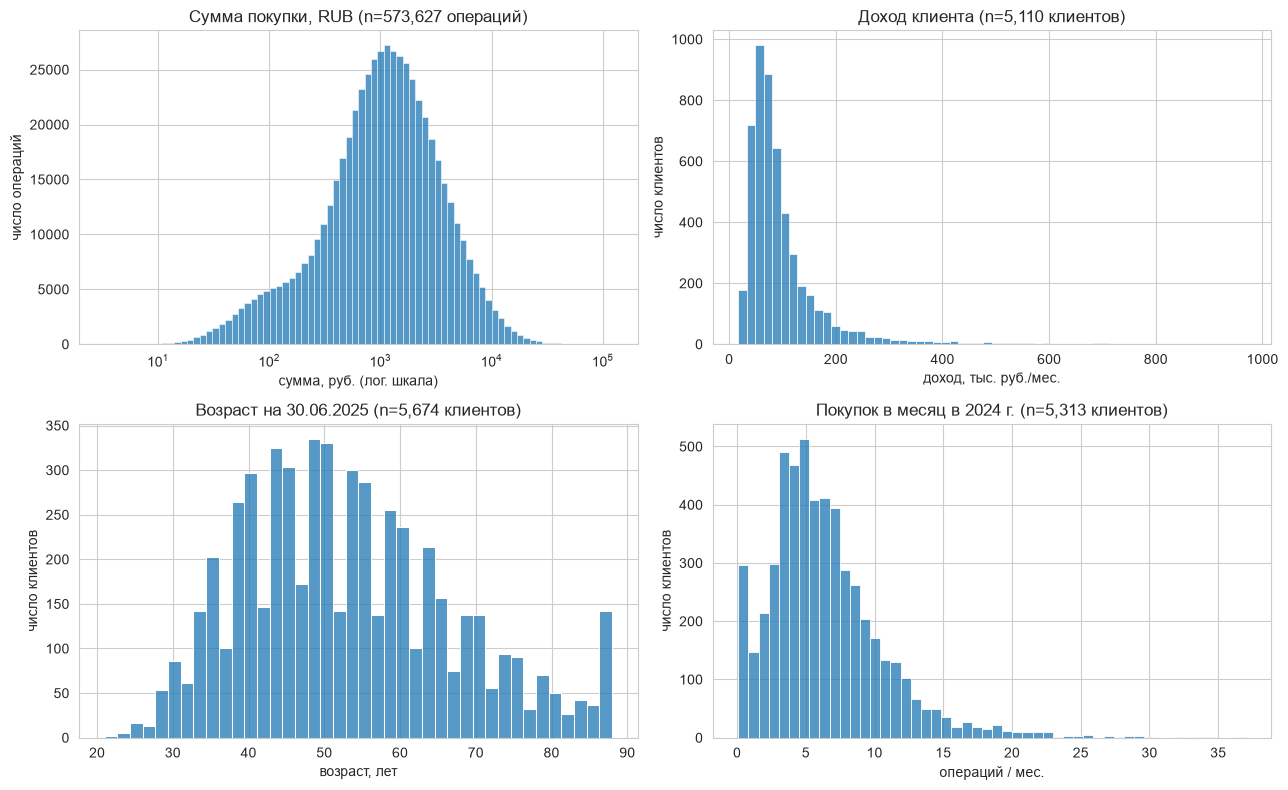

In [149]:
rub = purchases[purchases["currency"] == "RUB"]
txn_per_client_m = purchases[purchases["period"] == "база 2024"].groupby("client_id").size() / 12

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(rub["amount"], bins=80, log_scale=True, ax=axes[0, 0])
axes[0, 0].set(title=f"Сумма покупки, RUB (n={len(rub):,} операций)", xlabel="сумма, руб. (лог. шкала)", ylabel="число операций")
sns.histplot(df_clients["monthly_income"] / 1000, bins=60, ax=axes[0, 1])
axes[0, 1].set(title=f"Доход клиента (n={df_clients['monthly_income'].notna().sum():,} клиентов)", xlabel="доход, тыс. руб./мес.", ylabel="число клиентов")
sns.histplot(df_clients["age"], bins=40, ax=axes[1, 0])
axes[1, 0].set(title=f"Возраст на 30.06.2025 (n={len(df_clients):,} клиентов)", xlabel="возраст, лет", ylabel="число клиентов")
sns.histplot(txn_per_client_m, bins=50, ax=axes[1, 1])
axes[1, 1].set(title=f"Покупок в месяц в 2024 г. (n={len(txn_per_client_m):,} клиентов)", xlabel="операций / мес.", ylabel="число клиентов")
plt.tight_layout(); plt.show()

In [151]:
def describe_robust(s, unit):
    s = s.dropna()
    return pd.Series({"n": len(s), "медиана": s.median(), "Q1": s.quantile(.25), "Q3": s.quantile(.75),
                      "IQR": s.quantile(.75) - s.quantile(.25), "среднее": s.mean(), "асимметрия": s.skew(), "ед.": unit})

pd.DataFrame({
    "amount (RUB, успешные)": describe_robust(rub["amount"], "руб."),
    "monthly_income": describe_robust(df_clients["monthly_income"], "руб./мес."),
    "age": describe_robust(df_clients["age"], "лет"),
    "покупок/мес. 2024": describe_robust(txn_per_client_m, "опер./мес."),
}).T.round(2)

,n,медиана,Q1,Q3,IQR,среднее,асимметрия,ед.
"amount (RUB, успешные)",573627,1093.12,492.485,2292.485,1800.0,1921.880228,4.962729,руб.
monthly_income,5110,76200.0,54800.0,111900.0,57100.0,99123.248532,3.694786,руб./мес.
age,5674,51.0,43.0,62.0,19.0,53.176419,0.520091,лет
покупок/мес. 2024,5313,5.666667,3.666667,8.416667,4.75,6.406926,1.512916,опер./мес.


In [152]:
sat = df_clients["satisfaction_score"].dropna()
print(f"satisfaction_score (n={len(sat)} ответивших из {len(df_clients)}): медиана={sat.median():.0f}, "
      f"мода={sat.mode().iat[0]:.0f}, Q1–Q3={sat.quantile(.25):.0f}–{sat.quantile(.75):.0f}")
print("распределение, %:", (sat.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())

satisfaction_score (n=2322 ответивших из 5674): медиана=3, мода=5, Q1–Q3=2–5
распределение, %: {1.0: 12.1, 2.0: 20.1, 3.0: 20.3, 4.0: 19.3, 5.0: 28.2}


**Выбор мер.** Сумма, доход и число покупок сильно скошены вправо (асимметрия > 1, длинный хвост), поэтому
центр описываем **медианой**, разброс — **IQR**: среднее тянется хвостом. Возраст близок к симметричному,
для него среднее и медиана почти совпадают. `satisfaction_score` — порядковая шкала: расстояния между
баллами не равны, поэтому среднее не считаем; только медиана, мода и квартили.

### 5.2. Частотные характеристики категориальных признаков

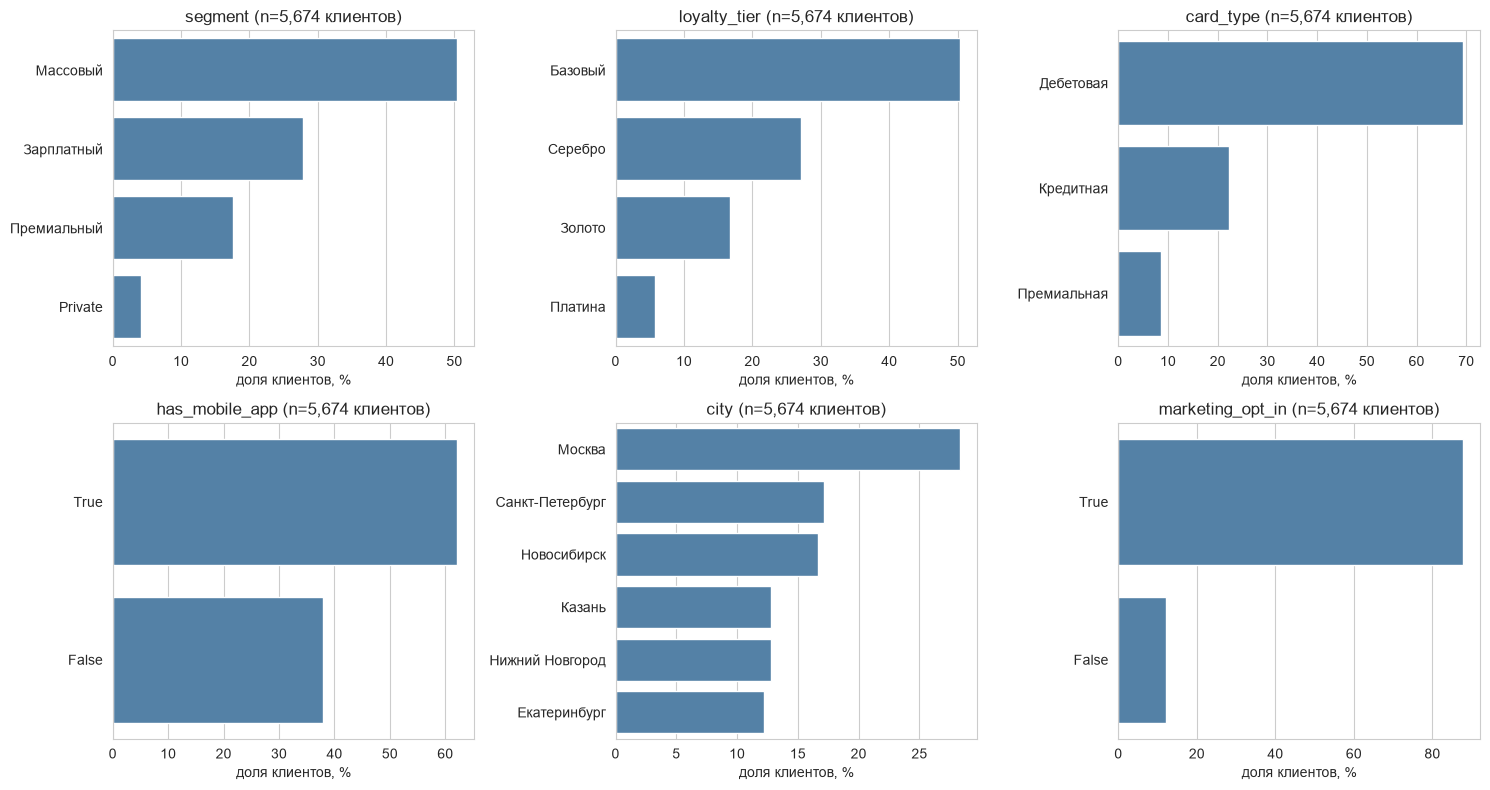

In [153]:
cols = ["segment", "loyalty_tier", "card_type", "has_mobile_app", "city", "marketing_opt_in"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cols):
    vc = df_clients[col].value_counts(normalize=True) * 100
    sns.barplot(x=vc.values, y=vc.index.astype(str), ax=ax, color="steelblue")
    ax.set(title=f"{col} (n={len(df_clients):,} клиентов)", xlabel="доля клиентов, %", ylabel="")
plt.tight_layout(); plt.show()

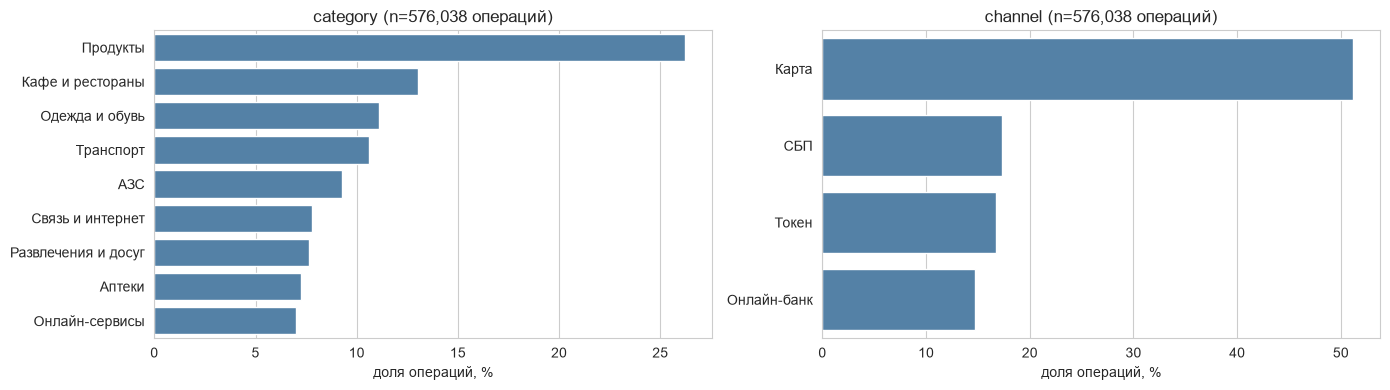

has_mobile_app  нет приложения, %  есть приложение, %
segment                                              
Private                      37.9                62.1
Зарплатный                   38.1                61.9
Массовый                     37.0                63.0
Премиальный                  40.0                60.0


In [154]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ["category", "channel"]):
    vc = purchases[col].value_counts(normalize=True) * 100
    sns.barplot(x=vc.values, y=vc.index, ax=ax, color="steelblue")
    ax.set(title=f"{col} (n={len(purchases):,} операций)", xlabel="доля операций, %", ylabel="")
plt.tight_layout(); plt.show()
print(pd.crosstab(df_clients["segment"], df_clients["has_mobile_app"], normalize="index").mul(100).round(1)
      .rename(columns={True: "есть приложение, %", False: "нет приложения, %"}))

### 5.3. Динамика по месяцам

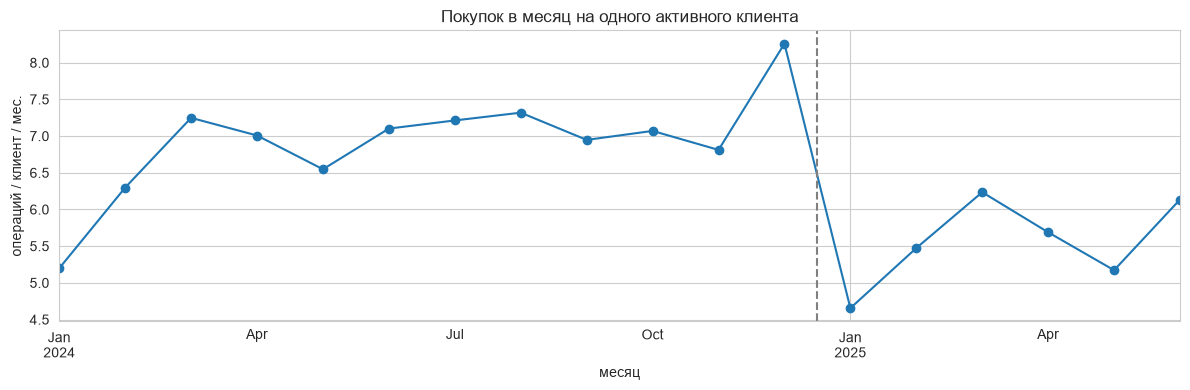

покупок всего: янв–июн 2024 189034 | янв–июн 2025 167558 | изменение год к году -11.4%
сезонность: среднемесячное H1 2024 / среднемесячное 2024 = -7.4%


In [155]:
active = purchases.groupby("month")["client_id"].nunique()
monthly = purchases.groupby("month").size()
per_client = (monthly / active)

fig, ax = plt.subplots(figsize=(12, 4))
per_client.plot(marker="o", ax=ax)
ax.axvline(pd.Period("2025-01", "M").ordinal - 0.5, color="grey", ls="--")
ax.set(title="Покупок в месяц на одного активного клиента", xlabel="месяц", ylabel="операций / клиент / мес.")
plt.tight_layout(); plt.show()

h1_24 = purchases[purchases["txn_datetime"] < "2024-07-01"].groupby("month").size().values
h1_25 = purchases[purchases["txn_datetime"] >= "2025-01-01"].groupby("month").size().values
print("покупок всего: янв–июн 2024", h1_24.sum(), "| янв–июн 2025", h1_25.sum(),
      f"| изменение год к году {h1_25.sum() / h1_24.sum() - 1:+.1%}")
print(f"сезонность: среднемесячное H1 2024 / среднемесячное 2024 = "
      f"{(h1_24.sum() / 6) / (purchases['period'].eq('база 2024').sum() / 12) - 1:+.1%}")

В данных выражена сезонность: декабрь — пик, январь — провал, второе полугодие выше первого. Поэтому даже
без реального снижения сравнение «январь–июнь» со «всем годом» даёт около −7% (вывод ячейки выше). Это учитываем при
выборе порога падения (раздел 6).

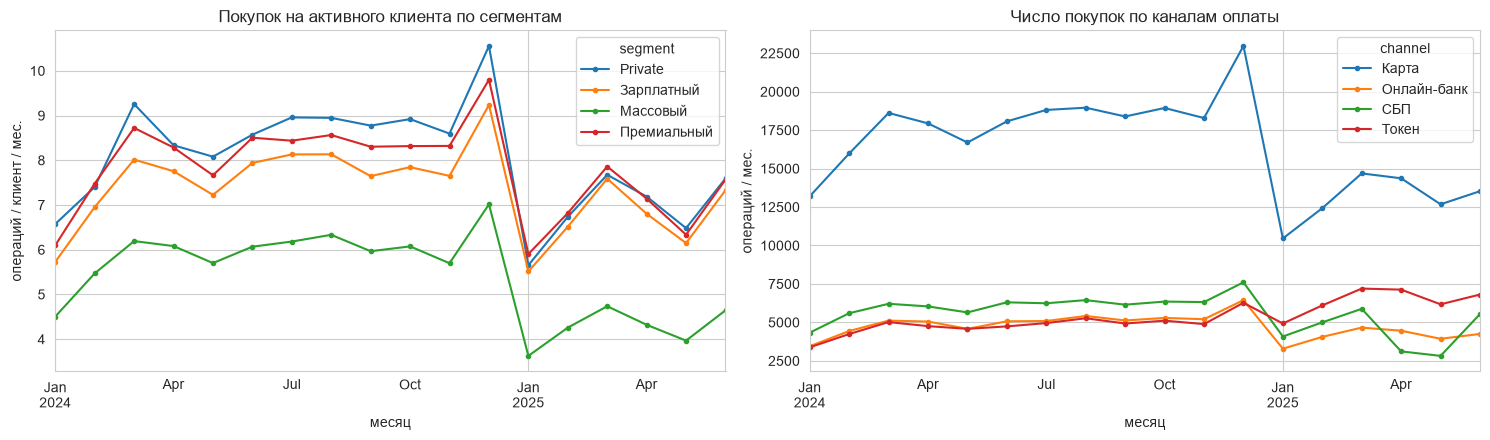

In [157]:
seg_m = purchases.groupby(["month", "segment"]).size() / purchases.groupby(["month", "segment"])["client_id"].nunique()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
seg_m.unstack().plot(marker=".", ax=axes[0])
axes[0].set(title="Покупок на активного клиента по сегментам", xlabel="месяц", ylabel="операций / клиент / мес.")
ch = purchases.groupby(["month", "channel"]).size().unstack()
ch.plot(marker=".", ax=axes[1])
axes[1].set(title="Число покупок по каналам оплаты", xlabel="месяц", ylabel="операций / мес.")
plt.tight_layout(); plt.show()

* Массовый сегмент — единственный, где уровень 2025 г. заметно ниже того же месяца 2024 г.; у остальных
  сегментов январь–июнь 2025 повторяет январь–июнь 2024.
* Каналы: с января 2025 «Карта» падает, а «Токен» растёт примерно на столько же — клиенты переходят с
  пластика на оплату телефоном. Это смена канала, а не снижение активности.
* СБП: провал в апреле–мае 2025 у всех и восстановление в июне — похоже на временный технический сбой,
  а не на поведение клиентов.

### 5.4. Разрезы и связи между признаками

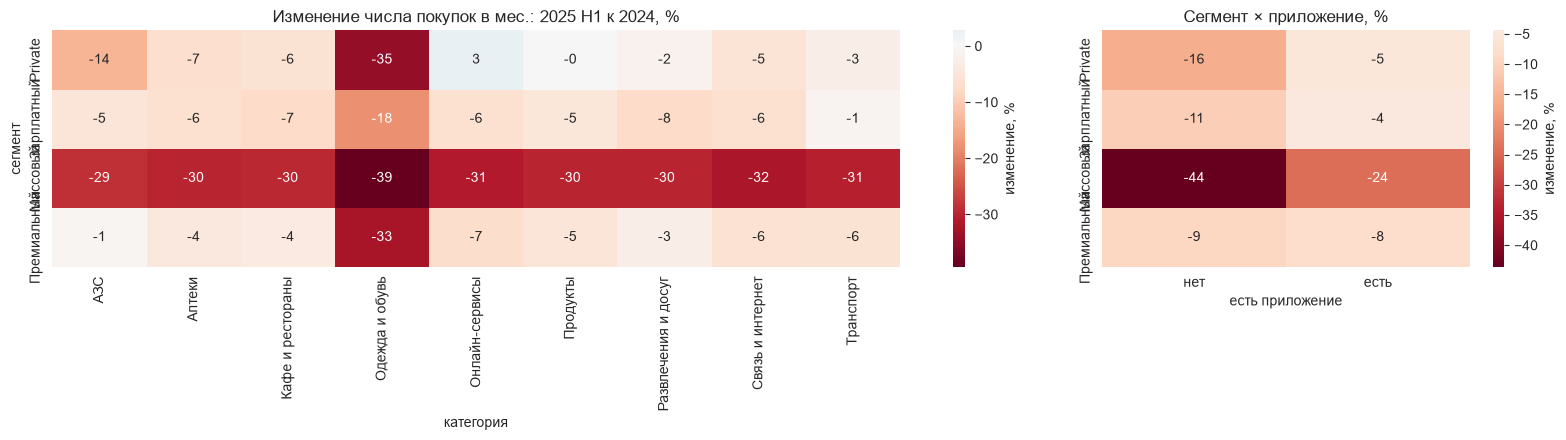

In [158]:
def yoy(df, by):
    t = df.groupby(by + ["period"]).size().unstack("period")
    t = t.assign(**{"изм_%": ((t["оценка 2025 H1"] / 6) / (t["база 2024"] / 12) - 1) * 100})
    return t["изм_%"].unstack() if len(by) > 1 else t["изм_%"]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [3, 1.3]})
sns.heatmap(yoy(purchases, ["segment", "category"]), annot=True, fmt=".0f", cmap="RdBu", center=0, ax=axes[0],
            cbar_kws={"label": "изменение, %"})
axes[0].set(title="Изменение числа покупок в мес.: 2025 H1 к 2024, %", xlabel="категория", ylabel="сегмент")
sns.heatmap(yoy(purchases, ["segment", "has_mobile_app"]).rename(columns={True: "есть", False: "нет"}), annot=True, fmt=".0f", cmap="RdBu", center=0, ax=axes[1],
            cbar_kws={"label": "изменение, %"})
axes[1].set(title="Сегмент × приложение, %", xlabel="есть приложение", ylabel="")
plt.tight_layout(); plt.show()

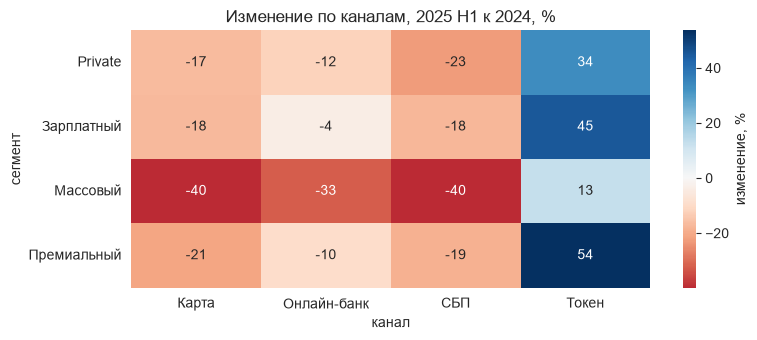

city {'Екатеринбург': -14.2, 'Казань': -14.3, 'Москва': -19.1, 'Нижний Новгород': -17.1, 'Новосибирск': -24.9, 'Санкт-Петербург': -16.5}
loyalty_tier {'Базовый': -23.4, 'Золото': -7.8, 'Платина': -8.1, 'Серебро': -17.7}
card_type {'Дебетовая': -20.2, 'Кредитная': -14.9, 'Премиальная': -9.2}
age_group {'до 30': -13.7, '31–45': -14.5, '46–60': -18.5, '60+': -22.6}
income_source {'Зарплата в другом банке': -22.7, 'Зарплата в нашем банке': -12.7, 'Не указан': -22.4}


In [159]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(yoy(purchases, ["segment", "channel"]), annot=True, fmt=".0f", cmap="RdBu", center=0, ax=ax,
            cbar_kws={"label": "изменение, %"})
ax.set(title="Изменение по каналам, 2025 H1 к 2024, %", xlabel="канал", ylabel="сегмент")
plt.tight_layout(); plt.show()
for col in ["city", "loyalty_tier", "card_type", "age_group", "income_source"]:
    print(col, yoy(purchases, [col]).round(1).to_dict())

* «Одежда и обувь» падает во **всех** сегментах (≈ −18…−39%), а остальные категории у немассовых сегментов
  меняются в пределах сезонной нормы — отдельная причина, связанная с категорией.
* В массовом сегменте падают **все** категории и все каналы примерно одинаково (≈ −30%) — общее снижение
  пользования картой, сильнее у клиентов без приложения.
* Город, уровень лояльности, тип карты, возраст и источник дохода тоже дают разницу, но её нужно проверить на
  смешение с сегментом (раздел 8).

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

**Что считаем.** Активность клиента — **число успешных покупок по карте в месяц** (status = «успешно»,
все каналы и валюты).

**Как.** Для каждого клиента:
* `rate_base` = покупок в 2024 г. / месяцев «экспозиции» в 2024 г.;
* `rate_eval` = покупок в январе–июне 2025 г. / месяцев экспозиции в этом окне;
* `change` = `rate_eval / rate_base − 1` (−0,4 = активность упала на 40%).

Окна разной длины (12 и 6 месяцев), поэтому сравниваем не количества, а **частоту в месяц**. Экспозиция
начинается с `card_open_date`: до открытия текущей карты операций нет ни у одного клиента (проверка ниже),
поэтому клиента, открывшего карту в ноябре 2024 г., нельзя делить на 12 месяцев — это дало бы ложный «рост».

**На ком.** Клиенты из справочника с экспозицией в базовом периоде не меньше 3 месяцев (иначе база слишком
мала, чтобы говорить о падении).

**Почему число операций, а не сумма.** Задача — «стали реже пользоваться картой»; это частота. Число операций
не зависит от валюты (курсов нет) и от крупных чеков (выбросы по сумме не влияют).

**Порог «снижения».** Сезонность сама даёт около −7% (раздел 5.3), поэтому падением считаем
`change ≤ −30%` — в несколько раз больше сезонного эффекта. Для группы G3, где причина — одна категория,
общее снижение требуем мягче: `change ≤ −15%` (вдвое больше сезонного).

**Чего метрика не видит:**
* падение **суммы** при том же числе покупок (клиент платит картой, но только мелочь, а крупное — в другом банке);
* перенос части покупок на наличные или карту другого банка, если число операций у нас не изменилось;
* временный провал внутри окна, который восстановился (например, СБП в апреле–мае) — усредняется;
* клиентов без базы: открыли карту позже сентября 2024 г.;
* ушедших клиентов: их нет в справочнике;
* смену канала (карта → токен) метрика правильно **не считает** падением, но и не показывает её.

In [161]:
first_txn = purchases.groupby("client_id")["txn_datetime"].min()
print("операций раньше card_open_date:",
      (purchases["txn_datetime"] < purchases["client_id"].map(df_clients.set_index("client_id")["card_open_date"])).sum())

def exposure_months(start, a, b):
    st = start.clip(lower=a)
    return ((b - st).dt.days.clip(lower=0)) / DAYS_IN_MONTH

cm = df_clients.set_index("client_id").copy()
cm["months_base"] = exposure_months(cm["card_open_date"], BASE_START, BASE_END)
cm["months_eval"] = exposure_months(cm["card_open_date"], EVAL_START, EVAL_END)

purchases["is_clothes"] = purchases["category"].eq("Одежда и обувь")
cnt = purchases.pivot_table(index="client_id", columns="period", values="txn_id", aggfunc="size", fill_value=0)
cnt_cl = purchases[purchases["is_clothes"]].pivot_table(index="client_id", columns="period", values="txn_id",
                                                         aggfunc="size", fill_value=0)
cm["n_base"] = cnt["база 2024"].reindex(cm.index).fillna(0)
cm["n_eval"] = cnt["оценка 2025 H1"].reindex(cm.index).fillna(0)
cm["n_base_clothes"] = cnt_cl["база 2024"].reindex(cm.index).fillna(0)
cm["n_eval_clothes"] = cnt_cl["оценка 2025 H1"].reindex(cm.index).fillna(0)

MIN_BASE_MONTHS = 3
has_base = cm["months_base"] >= MIN_BASE_MONTHS
cm["rate_base"] = (cm["n_base"] / cm["months_base"]).where(has_base)
cm["rate_eval"] = cm["n_eval"] / cm["months_eval"]
cm["change"] = cm["rate_eval"] / cm["rate_base"] - 1

# составляющие для описания «что произошло»
cm["rate_base_clothes"] = (cm["n_base_clothes"] / cm["months_base"]).where(has_base)
cm["rate_eval_clothes"] = cm["n_eval_clothes"] / cm["months_eval"]
cm["rate_base_other"] = cm["rate_base"] - cm["rate_base_clothes"]
cm["rate_eval_other"] = cm["rate_eval"] - cm["rate_eval_clothes"]
cm["change_other"] = cm["rate_eval_other"] / cm["rate_base_other"] - 1
last2 = purchases[purchases["txn_datetime"] >= "2025-05-01"].groupby("client_id").size() / 2
cm["rate_last2"] = last2.reindex(cm.index).fillna(0)          # май–июнь 2025, покупок в месяц
cm["last2_to_base"] = cm["rate_last2"] / cm["rate_base"]

DROP = -0.30
cm["dropped"] = cm["change"] <= DROP
print(f"клиентов в справочнике: {len(cm)}, с базой ≥ {MIN_BASE_MONTHS} мес.: {has_base.sum()}, "
      f"rate_base = 0 среди них: {(cm.loc[has_base, 'rate_base'] == 0).sum()}")
v = cm[has_base & (cm["rate_base"] > 0)]
print(f"падение ≤ {DROP:.0%}: {v['dropped'].sum()} из {len(v)} клиентов с базой ({v['dropped'].mean():.1%})")
print(f"медиана change: {v['change'].median():+.1%}, IQR: {v['change'].quantile(.25):+.1%} … {v['change'].quantile(.75):+.1%}")

операций раньше card_open_date: 0
клиентов в справочнике: 5674, с базой ≥ 3 мес.: 5134, rate_base = 0 среди них: 0
падение ≤ -30%: 2056 из 5134 клиентов с базой (40.0%)
медиана change: -20.6%, IQR: -52.5% … +3.1%


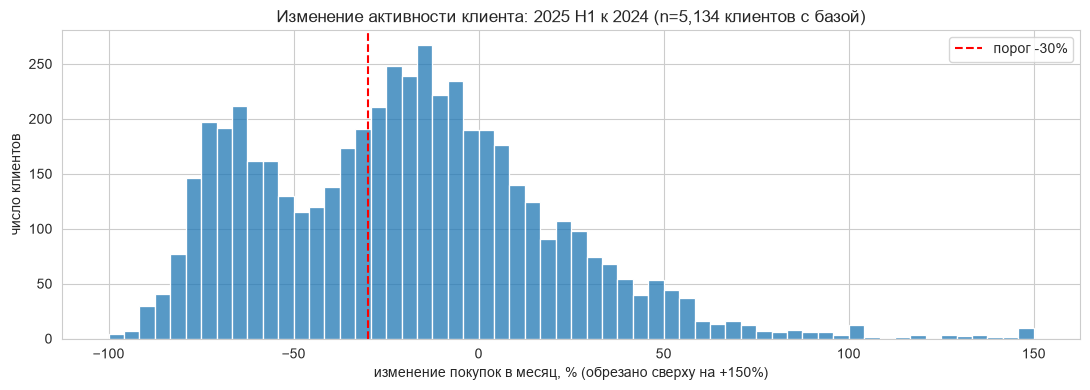

доля клиентов с падением ≤ −30% по сегменту × приложению, % (знаменатель — клиенты ячейки с базой):
has_mobile_app  False  True 
segment                     
Private          36.8   21.5
Зарплатный       30.7   19.5
Массовый         70.1   44.0
Премиальный      32.3   24.4


In [162]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.histplot(v["change"].clip(upper=1.5) * 100, bins=60, ax=ax)
ax.axvline(DROP * 100, color="red", ls="--", label=f"порог {DROP:.0%}")
ax.set(title=f"Изменение активности клиента: 2025 H1 к 2024 (n={len(v):,} клиентов с базой)",
       xlabel="изменение покупок в месяц, % (обрезано сверху на +150%)", ylabel="число клиентов")
ax.legend(); plt.tight_layout(); plt.show()

print("доля клиентов с падением ≤ −30% по сегменту × приложению, % (знаменатель — клиенты ячейки с базой):")
print(v.pivot_table(index="segment", columns="has_mobile_app", values="dropped", aggfunc="mean").mul(100).round(1))

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

Из разделов 5–6 видно три разных механизма падения:
1. **Массовый сегмент без приложения**: падают все категории и каналы, к маю–июню 2025 г. у многих активность
   почти исчезла — клиент перестаёт пользоваться картой.
2. **Массовый сегмент с приложением**: тоже падают все категории, но мягче и без «обнуления».
3. **Немассовые сегменты** (Зарплатный, Премиальный, Private): общая активность в норме, но клиенты перестали
   покупать одежду и обувь по нашей карте.

Механизмы пересекаются: у клиента массового сегмента может одновременно упасть всё и исчезнуть одежда.
Сначала считаем пересечения условий «что произошло», затем назначаем каждого клиента ровно в одну группу
по приоритету.

**Общие условия для любой группы** (кандидат в кампанию): клиент есть в справочнике, есть согласие на
маркетинг, нет конфликта версий записи, база ≥ 3 мес. и в 2024 г. была хотя бы одна покупка.

In [163]:
cand = cm[has_base & (cm["rate_base"] > 0) & cm["marketing_opt_in"] & ~cm["id_conflict"]].copy()

# что произошло (характер падения)
cand["fade_out"]    = (cand["change"] <= DROP) & (cand["last2_to_base"] <= 0.5)   # сошла почти на нет к концу периода
cand["broad_drop"]  = (cand["change"] <= DROP) & (cand["change_other"] <= DROP)   # падение по всем категориям, не только одежда
cand["clothes_stop"] = (cand["rate_base_clothes"] >= 0.5) & (cand["rate_eval_clothes"] <= 0.2 * cand["rate_base_clothes"])
# кто это
cand["mass_noapp"] = (cand["segment"] == "Массовый") & ~cand["has_mobile_app"]
cand["mass_app"]   = (cand["segment"] == "Массовый") & cand["has_mobile_app"]
cand["non_mass"]   = cand["segment"] != "Массовый"

print("кандидатов:", len(cand))
print("пересечения характера падения (число клиентов):")
print(pd.crosstab([cand["fade_out"], cand["broad_drop"]], cand["clothes_stop"], margins=True))

кандидатов: 4479
пересечения характера падения (число клиентов):
clothes_stop         False  True   All
fade_out broad_drop                   
False    False        2556   293  2849
         True          329    54   383
True     False          21    33    54
         True          990   203  1193
All                   3896   583  4479


In [164]:
GROUPS = {
    "G1_mass_noapp_fadeout": cand["mass_noapp"] & cand["fade_out"],
    "G2_mass_app_broad_drop": cand["mass_app"] & cand["broad_drop"],
    "G3_nonmass_clothes_stop": cand["non_mass"] & cand["clothes_stop"] & (cand["change"] <= -0.15),
}
# приоритет: порядок словаря (более глубокое и общее падение — раньше)
cand["group"] = None
for g, m in GROUPS.items():
    cand.loc[m & cand["group"].isna(), "group"] = g

multi = pd.DataFrame(GROUPS).sum(axis=1)
print("клиентов, подходящих под 2+ правила групп:", (multi > 1).sum())
print("клиентов массового сегмента в G1/G2, у которых также исчезла одежда:",
      (cand["group"].isin(["G1_mass_noapp_fadeout", "G2_mass_app_broad_drop"]) & cand["clothes_stop"]).sum())
cand["group"].value_counts()

клиентов, подходящих под 2+ правила групп: 0
клиентов массового сегмента в G1/G2, у которых также исчезла одежда: 157


group
G2_mass_app_broad_drop     573
G1_mass_noapp_fadeout      507
G3_nonmass_clothes_stop    263
Name: count, dtype: int64

In [165]:
BUDGET, MIN_GROUP = 2000, 150
camp = cand[cand["group"].notna()].copy()
camp["lost_per_month"] = camp["rate_base"] - camp["rate_eval"]
if len(camp) > BUDGET:   # если не помещаемся в бюджет — оставляем клиентов с наибольшей потерей покупок
    camp = camp.sort_values("lost_per_month", ascending=False).head(BUDGET)
sizes = camp["group"].value_counts()
assert sizes.min() >= MIN_GROUP and len(camp) <= BUDGET and camp.index.is_unique
print(f"в кампании {len(camp)} клиентов (бюджет {BUDGET}); минимальная группа {sizes.min()} (порог {MIN_GROUP})")

summary = camp.groupby("group").agg(
    клиентов=("rate_base", "size"),
    покупок_в_мес_2024=("rate_base", "median"),
    покупок_в_мес_2025H1=("rate_eval", "median"),
    изменение_медиана_pct=("change", lambda s: s.median() * 100),
    изменение_без_одежды_pct=("change_other", lambda s: s.median() * 100),
    одежда_2024=("rate_base_clothes", "median"),
    одежда_2025H1=("rate_eval_clothes", "median"),
    май_июнь_к_базе_pct=("last2_to_base", lambda s: s.median() * 100),
).round(2)
summary

в кампании 1343 клиентов (бюджет 2000); минимальная группа 263 (порог 150)


,клиентов,покупок_в_мес_2024,покупок_в_мес_2025H1,изменение_медиана_pct,изменение_без_одежды_pct,одежда_2024,одежда_2025H1,май_июнь_к_базе_pct
group,,,,,,,,
G1_mass_noapp_fadeout,507,4.66,1.51,-67.76,-68.07,0.42,0.17,15.13
G2_mass_app_broad_drop,573,5.41,2.02,-61.48,-62.09,0.50,0.17,30.23
G3_nonmass_clothes_stop,263,7.24,4.04,-38.10,-19.12,1.50,0.17,60.12


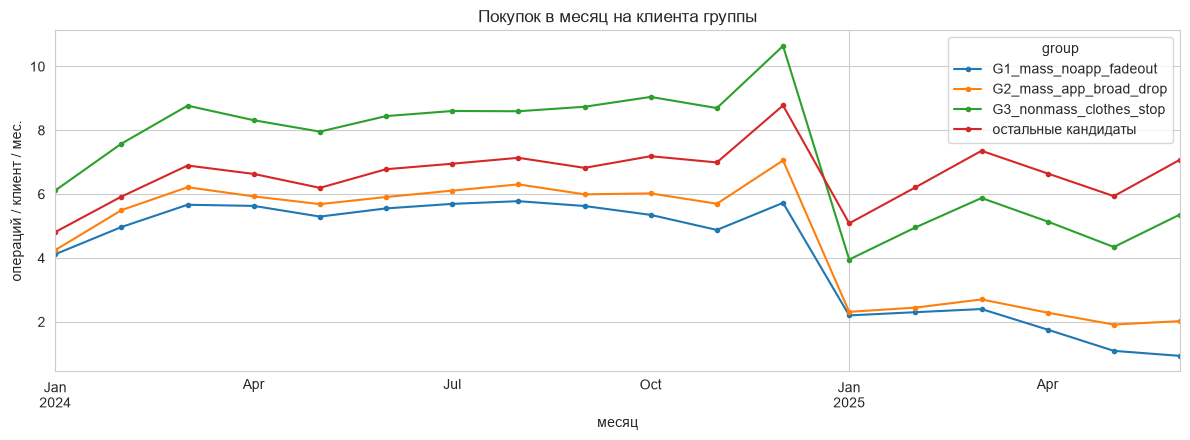

покупок одежды на клиента группы, янв-24 / июн-24 / янв-25 / июн-25:
group    G1_mass_noapp_fadeout  G2_mass_app_broad_drop  G3_nonmass_clothes_stop
month                                                                          
2024-01                   0.39                    0.40                     1.33
2024-06                   0.55                    0.57                     1.78
2025-01                   0.20                    0.21                     0.11
2025-06                   0.09                    0.21                     0.17


In [166]:
fig, ax = plt.subplots(figsize=(12, 4.5))
mon = purchases[purchases["client_id"].isin(camp.index)].copy()
mon["group"] = mon["client_id"].map(camp["group"])
rest = purchases[purchases["client_id"].isin(cand.index[cand["group"].isna()])]
series = (mon.groupby(["month", "group"]).size() / camp["group"].value_counts()).unstack()
series["остальные кандидаты"] = rest.groupby("month").size() / cand["group"].isna().sum()
series.plot(marker=".", ax=ax)
ax.set(title="Покупок в месяц на клиента группы", xlabel="месяц", ylabel="операций / клиент / мес.")
plt.tight_layout(); plt.show()

clothes = (mon[mon["is_clothes"]].groupby(["month", "group"]).size() / camp["group"].value_counts()).unstack()
print("покупок одежды на клиента группы, янв-24 / июн-24 / янв-25 / июн-25:")
print(clothes.loc[[pd.Period(m, "M") for m in ["2024-01", "2024-06", "2025-01", "2025-06"]]].round(2))

**Группы и правила** (все поля считаются из `clients.csv` и `transactions.csv`):

| группа | кто это | что произошло | правило |
|---|---|---|---|
| G1 | Массовый сегмент **без** мобильного приложения | активность сошла почти на нет к концу периода | `segment = Массовый` и `has_mobile_app = Нет` и покупок в мес. в 2025 H1 ≤ 70% от 2024 и в мае–июне 2025 ≤ 50% от 2024 |
| G2 | Массовый сегмент **с** приложением | равномерное падение по всем категориям (не только одежда) | `segment = Массовый` и `has_mobile_app = Да` и снижение ≤ −30% в целом и ≤ −30% без учёта одежды |
| G3 | Зарплатный, Премиальный, Private | перестали покупать одежду и обувь по карте, остальное почти не изменилось | `segment ≠ Массовый` и в 2024 г. ≥ 0,5 покупки одежды в мес. и в 2025 H1 ≤ 20% от этого уровня и общее снижение ≤ −15% |

Пороги (−30%, 50%, 20%) уточняют правило, а не составляют его: содержание группы — кто это и как именно
упала активность. Приоритет при пересечении: G1 → G2 → G3. По построению сегмент и приложение делят
группы, поэтому формальных пересечений нет; содержательное пересечение — у части клиентов G1/G2 одежда тоже
исчезла (число выше), но для них это часть общего ухода, а не отдельная причина.

**Что предлагать:** G1 — вернуть к использованию карты как основной (кэшбэк на повседневные категории,
установка приложения); G2 — коммуникация через приложение, персональные предложения на обычные категории;
G3 — предложение в категории «Одежда и обувь» (повышенный кэшбэк, партнёрские магазины).

### 7.1. Кого в кампанию не берём и почему

In [168]:
reasons = pd.Series("в кампании", index=cm.index, dtype="object")
not_in = cm.index.difference(camp.index)
r = pd.Series(index=not_in, dtype="object")
r[~has_base.reindex(not_in)] = "нет базы: карта открыта позже сентября 2024 г."
r[r.isna() & (cm.loc[not_in, "rate_base"] == 0)] = "нет покупок в 2024 г."
r[r.isna() & cm.loc[not_in, "id_conflict"]] = "противоречивые версии записи клиента"
r[r.isna() & ~cm.loc[not_in, "marketing_opt_in"]] = "нет согласия на маркетинговую коммуникацию"
r[r.isna() & (cm.loc[not_in, "change"] > -0.15)] = "снижения нет или оно в пределах сезонности (> −15%)"
r[r.isna() & (cm.loc[not_in, "change"] > DROP)] = "умеренное снижение (−15…−30%) без выраженной причины"
r[r.isna()] = "падение ≤ −30%, но не подходит под правило группы"
reasons[not_in] = r
excl = reasons.value_counts().rename("клиентов").to_frame()
excl["доля_%"] = (excl["клиентов"] / len(cm) * 100).round(1)
print("знаменатель — клиенты справочника:", len(cm))
display(excl)

orph = df_transactions.loc[~df_transactions["in_directory"], "client_id"].nunique()
print(f"+ {orph} клиентов есть только в операциях (нет в справочнике действующих клиентов) — не берём")

leftover = cm.loc[reasons == "падение ≤ −30%, но не подходит под правило группы"]
print("\n«падение ≤ −30%, но не в группе» по сегменту:", leftover["segment"].value_counts().to_dict())
noconsent_drop = cm[~cm["marketing_opt_in"] & cm["dropped"]]
print("с падением ≤ −30%, но без согласия:", len(noconsent_drop))

знаменатель — клиенты справочника: 5674


,клиентов,доля_%
снижения нет или оно в пределах сезонности (> −15%),1950,34.4
в кампании,1343,23.7
умеренное снижение (−15…−30%) без выраженной причины,668,11.8
нет согласия на маркетинговую коммуникацию,641,11.3
нет базы: карта открыта позже сентября 2024 г.,540,9.5
"падение ≤ −30%, но не подходит под правило группы",518,9.1
противоречивые версии записи клиента,14,0.2


+ 326 клиентов есть только в операциях (нет в справочнике действующих клиентов) — не берём

«падение ≤ −30%, но не в группе» по сегменту: {'Зарплатный': 210, 'Массовый': 165, 'Премиальный': 121, 'Private': 22}
с падением ≤ −30%, но без согласия: 256


* **Без согласия на маркетинг** — коммуникация запрещена условием, даже если падение сильное.
* **Без базы** (карта открыта позже сентября 2024 г.) — не с чем сравнивать.
* **Противоречивые записи** (14 клиентов) — неясно, к какому сегменту относится клиент, а правило групп от него зависит.
* **Нет в справочнике** (ушедшие клиенты) — нет признаков и согласия; это задача удержания/возврата, а не активации.
* **Снижения нет или оно в пределах сезонности** — к ним же относятся клиенты, перешедшие с карты на токен:
  число покупок не упало, сменился только способ оплаты.
* **Умеренное снижение без выраженной причины** — падение меньше порога; кампания на них не окупит отдельную коммуникацию.
* **Падение ≤ −30%, но не под правило** — в основном немассовые клиенты с общим снижением, не связанным с одеждой:
  по этим сегментам в целом январь–июнь 2025 равен январю–июню 2024, то есть часть «падения» — сезонность базы
  и индивидуальный шум; признаками его объяснить не удалось, а без причины непонятно, что предлагать.
  Массовые клиенты в этой строке — те, у кого падение не прошло дополнительное условие своей группы.
* Клиенты, у которых в апреле–мае просела только СБП, отдельно не выделяются: это общий временный сбой.

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

Каждая гипотеза проверяется с поправкой на сегмент, потому что массовый сегмент распределён по признакам
неравномерно.

In [170]:
vv = v.copy()
def med(df, by):
    return (df.groupby(by, observed=True)["change"].median() * 100).round(1)

# H1: Новосибирск падает сильнее
print("H1 город. Медиана change, % — все сегменты:", med(vv, "city").to_dict())
print("    доля массового сегмента по городам, %:", (vv.groupby("city")["segment"].apply(lambda s: (s == "Массовый").mean()) * 100).round(0).to_dict())
print("    внутри массового сегмента:", med(vv[vv.segment == "Массовый"], "city").to_dict())

# H2: зарплата в другом банке
print("\nH2 источник дохода. Все:", med(vv, "income_source").to_dict())
print("    внутри массового:", med(vv[vv.segment == "Массовый"], "income_source").to_dict())
print("    внутри немассовых:", med(vv[vv.segment != "Массовый"], "income_source").to_dict())

# H3: давно не заходили в приложение
app = vv[vv["has_mobile_app"]].copy()
app["login"] = np.where(app["app_last_login"] < "2025-01-01", "последний вход в 2024", "заходил в 2025")
print("\nH3 давность входа в приложение (внутри сегмента):")
print(med(app, ["segment", "login"]).unstack())

# H4: переход карта -> токен = падение
tok = purchases.groupby(["client_id", "period", "channel"]).size().unstack(["period", "channel"], fill_value=0)
share_tok = (tok[("оценка 2025 H1", "Токен")] / tok["оценка 2025 H1"].sum(axis=1)) - \
            (tok[("база 2024", "Токен")] / tok["база 2024"].sum(axis=1))
vv["token_shift"] = share_tok.reindex(vv.index) >= 0.2
print("\nH4 сдвиг доли токена ≥ +20 п.п.: клиентов", vv["token_shift"].sum(),
      "| медиана change у них", round(vv.loc[vv.token_shift, "change"].median() * 100, 1),
      "% vs у остальных", round(vv.loc[~vv.token_shift, "change"].median() * 100, 1), "%")

# H5: СБП — устойчивое падение
sbp = purchases[purchases["channel"] == "СБП"].groupby("month").size()
print("\nH5 СБП, покупок в мес.: март-25", sbp[pd.Period("2025-03", "M")], "| апр-25", sbp[pd.Period("2025-04", "M")],
      "| май-25", sbp[pd.Period("2025-05", "M")], "| июн-25", sbp[pd.Period("2025-06", "M")])

H1 город. Медиана change, % — все сегменты: {'Екатеринбург': -17.3, 'Казань': -18.3, 'Москва': -21.0, 'Нижний Новгород': -19.7, 'Новосибирск': -28.2, 'Санкт-Петербург': -19.0}
    доля массового сегмента по городам, %: {'Екатеринбург': 44.0, 'Казань': 45.0, 'Москва': 45.0, 'Нижний Новгород': 45.0, 'Новосибирск': 88.0, 'Санкт-Петербург': 43.0}
    внутри массового сегмента: {'Екатеринбург': -31.1, 'Казань': -27.6, 'Москва': -44.9, 'Нижний Новгород': -32.6, 'Новосибирск': -32.6, 'Санкт-Петербург': -35.7}

H2 источник дохода. Все: {'Зарплата в другом банке': -26.8, 'Зарплата в нашем банке': -15.4, 'Не указан': -24.2}
    внутри массового: {'Зарплата в другом банке': -36.1, 'Зарплата в нашем банке': -36.6, 'Не указан': -31.7}
    внутри немассовых: {'Зарплата в другом банке': -13.2, 'Зарплата в нашем банке': -11.2, 'Не указан': -11.6}

H3 давность входа в приложение (внутри сегмента):
login        заходил в 2025  последний вход в 2024
segment                                           
Priv

| гипотеза | результат |
|---|---|
| Новосибирск падает сильнее других городов | **не подтвердилась**: там больше всего массового сегмента; внутри сегмента Новосибирск не хуже других городов |
| Падают клиенты, получающие зарплату в другом банке | **не подтвердилась**: внутри сегмента медианы по источнику дохода почти равны; разница в общей выборке — эффект сегмента |
| Падают те, кто давно не заходил в приложение | **не подтвердилась**: внутри сегмента медианы у «заходивших в 2025» и «последний вход в 2024» отличаются не более чем на 6 п.п., и знак разницы непостоянный; важно наличие приложения, а не давность входа |
| Рост токена — это потеря карточных клиентов | **не подтвердилась**: у клиентов, перешедших на токен, медианное изменение активности не хуже, чем у остальных; это смена канала |
| СБП стала причиной устойчивого падения | **не подтвердилась**: провал только в апреле–мае 2025 г., в июне уровень вернулся — временный сбой |

Конкретные числа к каждой строке — в выводе ячейки выше.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [171]:
%pip install pyarrow
df_clients.to_parquet("clean_clients.parquet", index=False)
df_transactions.to_parquet("clean_transactions.parquet", index=False)
out_cm = cm.drop(columns=[c for c in cm.columns if c in ["age_group"]]).reset_index()
out_cm["group"] = out_cm["client_id"].map(camp["group"])
out_cm["exclusion_reason"] = out_cm["client_id"].map(reasons)
out_cm.to_parquet("client_metrics.parquet", index=False)
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
campaign = camp.reset_index()[["client_id", "group"]]
campaign.to_csv("campaign_list.csv", index=False, encoding="utf-8")

chk = pd.read_csv("campaign_list.csv")
print("campaign_list.csv:", len(chk), "строк, уникальных client_id:", chk["client_id"].nunique(),
      "| группы:", chk["group"].value_counts().to_dict())
print("cleaning_log.csv:", len(cleaning_log), "решений")


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
campaign_list.csv: 1343 строк, уникальных client_id: 1343 | группы: {'G2_mass_app_broad_drop': 573, 'G1_mass_noapp_fadeout': 507, 'G3_nonmass_clothes_stop': 263}
cleaning_log.csv: 16 решений
